# Adhoc API ingest

# Load holders

In [6]:
# import requests
# import pandas as pd
# import time

# try:
#     base_api_url = 'https://scan.tokenx.finance/api/v2/tokens/0x2f5c60bdE7A5ebD2b116BB03cB5232fA1Ea55F1C/holders'

#     headers = {
#         'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
#         'Accept': 'application/json'
#     }

#     all_holders = []
#     params = {}
#     page_count = 1

#     print("Starting scraping of all pages...")

#     while True:
#         print(f"Fetching page {page_count}...")
#         response = requests.get(base_api_url, headers=headers, params=params)
#         response.raise_for_status()
#         data = response.json()

#         items = data.get('items', [])
#         if not items:
#             break

#         # Extract decimals and total supply metadata from the first page
#         if page_count == 1:
#             token_info = items[0].get('token', {})
#             decimals = int(token_info.get('decimals', 18))
#             total_supply = float(token_info.get('total_supply', 0))
#             token_name = token_info.get('name')
#             token_symbol = token_info.get('symbol')

#         for item in items:
#             address_info = item.get('address', {})
#             raw_value = float(item.get('value', 0))
#             formatted_value = raw_value / (10 ** decimals)
#             share_pct = (raw_value / total_supply) * 100 if total_supply > 0 else 0.0

#             all_holders.append({
#                 'Address': address_info.get('hash'),
#                 'Balance': formatted_value,
#                 'Share %': f"{share_pct:.6f}%",
#                 'Raw Value': raw_value
#             })

#         # Handle pagination using next_page_params
#         next_page_params = data.get('next_page_params')
#         if next_page_params:
#             params = next_page_params
#             page_count += 1
#             time.sleep(0.5)  # Respectful delay between requests
#         else:
#             break

#     df_holders = pd.DataFrame(all_holders).drop_duplicates()
#     print(f"\nCompleted! Successfully scraped {page_count} pages.")
#     print(f"Token: {token_name} ({token_symbol})")
#     print(f"Total Unique Holders Scraped: {len(df_holders)}")
#     print(f"Total Calculated Supply: {df_holders['Balance'].sum():,.4f} (Expected: {total_supply / (10**decimals):,.4f})")

#     # Display top 15 results
#     display(df_holders.head(15))
# except Exception as e:
#     print(f"An error occurred during scraping: {e}")

In [7]:
# df_holders.loc[~df_holders['Address'].isin(ex)].merge(balance_sheet_df,left_on='Address',right_on='From',how='left')[['Balance','balance','in_bound_amount','out_bound_amount']].sum()

In [8]:
# balance_sheet_df.loc[balance_sheet_df['From'].isin(official_accs)]['out_bound_amount'].sum()

In [9]:
# balance_sheet_df.loc[~balance_sheet_df['From'].isin(ex)
#                      & balance_sheet_df['balance']>0].shape

In [10]:
# df_holders.rename(columns={'Address':'From'}).merge(balance_sheet_df,on='From',how='left').query(f'From=="{hof}"')

In [11]:
acc_48 = '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148' # Music Code
acc_merch_1 = '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB' # Handshake
acc_merch_2 = '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4' # Handshake
acc_merch_3 = '0xa66e830BC83c98A78AC20D1b705E8abE1C768195' # MYO
acc_merch_4 = '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41' # MYO
acc_merch_5 = '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc' # MYO

#official_accs = [acc_48,acc_merch_1,acc_merch_2,acc_merch_3,acc_merch_4,acc_merch_5]


vote_acc = '0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F'

hof = '0xaB4d90d445d2a875c96831d6c4392aA80150aCEf'
buu = '0x545bdc1851C09c21045d8B2cD3b17545B176E6a8'
hidden_buu = '0x38321F6C8DB96a672C8395AF996f0A97450c96C4'
my_acc = '0xc13e6b44e50091569684226b1dD312A1c749862E'


# Fetch transfers

In [12]:
import requests
import pandas as pd
import time
import json


vote_acc = '0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F'
hof = '0xaB4d90d445d2a875c96831d6c4392aA80150aCEf'
buu = '0x545bdc1851C09c21045d8B2cD3b17545B176E6a8'
hidden_buu = '0x38321F6C8DB96a672C8395AF996f0A97450c96C4'
my_acc = '0xc13e6b44e50091569684226b1dD312A1c749862E'
source = "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255"

def clean_and_deduplicate(dataframe, key_columns):
    """
    Removes duplicate entries based on a unique key column (e.g., 'Tx Hash' or 'Address').
    """
    if isinstance(key_columns,str):
        key_columns = [key_columns]

    if dataframe is None or dataframe.empty:
        return pd.DataFrame(columns=['Tx Hash', 'Block Hash', 'Timestamp', 'From', 'To', 'Value', 'Raw Value', 'Type'])
    initial_count = len(dataframe)
    deduped_df = dataframe.drop_duplicates(subset=key_columns, keep='first').reset_index(drop=True)
    print(f"Removed {initial_count - len(deduped_df)} duplicate rows. Total rows now: {len(deduped_df)}.")
    return deduped_df

def fetch_incremental_transfers(existing_df_transfers=None, token_address='0x2f5c60bdE7A5ebD2b116BB03cB5232fA1Ea55F1C', safety_overlap=20):
    """
    Fetches new token transfers incrementally or performs a full fetch from scratch if no existing dataframe is provided.
    Uses a safety_overlap depth check during incremental runs to prevent data loss.
    """
    base_transfers_url = f'https://scan.tokenx.finance/api/v2/tokens/{token_address}/transfers'
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
        'Accept': 'application/json'
    }

    is_from_scratch = existing_df_transfers is None or existing_df_transfers.empty

    if is_from_scratch:
        print("No pre-existing transfers detected. STARTING TRANSFER SCRAPING FROM SCRATCH...")
        existing_df_transfers = pd.DataFrame(columns=['Tx Hash', 'Block Hash', 'Timestamp','Method','From', 'To', 'Value', 'Raw Value', 'Type', 'log_index'])
    else:
        print(f"Incremental sync detected. Initializing lookback buffer check with safety overlap depth of {safety_overlap}...")

    existing_hashes = set(existing_df_transfers['Tx Hash'].values) if 'Tx Hash' in existing_df_transfers.columns else set()
    new_transfers = []
    params = {}
    page_count = 1
    stop_reached = False
    consecutive_matched_count = 0

    # if not is_from_scratch:
    #     try:

    #         with open("checkpoint.json", "r", encoding="utf-8") as f:
    #             params = json.load(f)
    #             print(params)
    #     except Exception as e:
    #         pass

    while not stop_reached:
        try:
            print(f"Fetching page {page_count}...")
            response = requests.get(base_transfers_url, headers=headers, params=params)
            response.raise_for_status()
            data = response.json()

            items = data.get('items', [])

            if not items:
                print("No more items returned by the API. Stopping.")
                break

            if page_count == 1 and items:
                token_info = items[0].get('token', {})
                decimals = int(token_info.get('decimals', 18))

            for item in items:
                tx_hash = item.get('tx_hash')

                # Only apply early stopping watermark if we are not building from scratch
                if not is_from_scratch:
                    if tx_hash in existing_hashes:
                        consecutive_matched_count += 1

                        if consecutive_matched_count >= safety_overlap:
                                print(f"Encountered {consecutive_matched_count} consecutive existing transactions. Stopping incremental fetch.")
                                stop_reached = True
                                break
                        else:
                            continue

                else:
                    consecutive_matched_count = 0



                from_addr = item.get('from', {}).get('hash')
                to_addr = item.get('to', {}).get('hash')
                raw_value = float(item.get('total', {}).get('value', 0) or item.get('value', 0))
                formatted_value = raw_value / (10 ** decimals)


                new_transfers.append({
                    'Tx Hash': tx_hash,
                    'Block Hash': item.get('block_hash'),
                    'Timestamp': item.get('timestamp'),
                    'Method' : item.get('method'),
                    'From': from_addr,
                    'To': to_addr,
                    'Value': formatted_value,
                    'Raw Value': raw_value,
                    'Type': item.get('type'),
                    'log_index': item.get('log_index')
                })

            if stop_reached:
                break
            
            next_page_params = data.get('next_page_params')
            if next_page_params:
                params = next_page_params
                page_count += 1
                time.sleep(0.5)
            else:
                print("Reached the last page of transfers.")
                break
        except Exception as e:
            print(e)
            # if next_page_params:
            #     with open("checkpoint.json", "w", encoding="utf-8") as f:
            #         json.dump(next_page_params, f, indent=2)
            #     print(f'watermark saved: {next_page_params}')
            #     new_df = pd.DataFrame(new_transfers)
            #     combined_df = pd.concat([new_df, existing_df_transfers], ignore_index=True)
            #     return  clean_and_deduplicate(combined_df, 'Tx Hash')

    if new_transfers:
        new_df = pd.DataFrame(new_transfers)
        print(f"Successfully retrieved {len(new_df)} new transfers across {page_count} pages.")
        combined_df = pd.concat([new_df, existing_df_transfers], ignore_index=True)
        return  clean_and_deduplicate(combined_df, ['Tx Hash','log_index'])
    else:
        print("No new transfers found. System is up to date.")
        return existing_df_transfers
        
        
        

    

In [13]:
try:
    df_transfers = pd.read_parquet('GE6_txn.parquet')
except Exception as e:
    df_transfers = None
df_transfers = fetch_incremental_transfers(existing_df_transfers=df_transfers)
df_transfers.to_parquet('GE6_txn.parquet')

df_transfers['Timestamp'] = pd.to_datetime(df_transfers['Timestamp'], utc=True)
df_transfers['Datetime'] = (
    df_transfers['Timestamp']
    .dt.tz_convert('Asia/Bangkok')
)

voter_list = df_transfers.query(f'To == "{vote_acc}"').drop_duplicates()['From'].unique()
official_accs = list(df_transfers.query('From == "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255"')['To'].unique())


df_transfers['Date'] = df_transfers['Datetime'].dt.date
df_transfers['Hour'] = df_transfers['Datetime'].dt.floor('h')

df_transfers['in_game'] = df_transfers['From'].apply(lambda x: 1 if x in voter_list else 0)
df_transfers['is_vote'] = (df_transfers['Method'] == 'vote').astype('int') #.apply(lambda row: 1 if row['Method'] == 'vote' else 0, axis=1)
df_transfers['is_transfer'] = (df_transfers['Method'] == 'transfer').astype('int')   #df_transfers.apply(lambda row: 1 if row['Method'] == 'transfer' else 0, axis=1)
df_transfers['is_multipleTransfer'] = (df_transfers['Method'] == 'multipleTransfer').astype('int') #df_transfers.apply(lambda row: 1 if row['Method'] == 'multipleTransfer' else 0, axis=1)
df_transfers['vote_amount'] = df_transfers.apply(lambda row: row['Value'] if row['Method'] == 'vote' else 0, axis=1)
df_transfers['transfer_amount'] = df_transfers.apply(lambda row: row['Value'] if row['Method'] == 'transfer' else 0, axis=1)
df_transfers['multipleTransfer_amount'] = df_transfers.apply(lambda row: row['Value'] if row['Method'] == 'multipleTransfer' else 0, axis=1)
df_transfers['minting_amount'] = df_transfers.apply(lambda row: row['Value'] if row['Method'] not in ['vote', 'transfer', 'multipleTransfer'] else 0, axis=1)
df_transfers['vote_amount_by_wallet_per_date'] = df_transfers.groupby(['From','Date'])['vote_amount'].transform('sum')
df_transfers['multipleTransfer_amount_by_wallet_per_date'] = df_transfers.groupby(['From','Date'])['multipleTransfer_amount'].transform('sum')
df_transfers['num_out_bound_txn_by_wallet_per_date'] = df_transfers.groupby(['From','Date'])['Tx Hash'].transform('count')

Incremental sync detected. Initializing lookback buffer check with safety overlap depth of 20...
Fetching page 1...
Fetching page 2...
Fetching page 3...
Fetching page 4...
Fetching page 5...
Fetching page 6...
Fetching page 7...
Fetching page 8...
Fetching page 9...
Fetching page 10...
Fetching page 11...
Fetching page 12...
Fetching page 13...
Encountered 20 consecutive existing transactions. Stopping incremental fetch.
Successfully retrieved 604 new transfers across 13 pages.
Removed 250 duplicate rows. Total rows now: 21416.


In [14]:
df_transfers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21416 entries, 0 to 21415
Data columns (total 24 columns):
 #   Column                                      Non-Null Count  Dtype                       
---  ------                                      --------------  -----                       
 0   Tx Hash                                     21416 non-null  object                      
 1   Block Hash                                  21416 non-null  object                      
 2   Timestamp                                   21416 non-null  datetime64[ns, UTC]         
 3   Method                                      21416 non-null  object                      
 4   From                                        21416 non-null  object                      
 5   To                                          21416 non-null  object                      
 6   Value                                       21416 non-null  float64                     
 7   Raw Value                               

In [15]:
df_transfers.groupby('Hour').agg(num_txn = ('Tx Hash', 'count'),
                                 vote_amount = ('vote_amount', 'sum'),
                                 transfer_amount = ('transfer_amount', 'sum'),
                                 multipleTransfer_amount = ('multipleTransfer_amount', 'sum')).sort_values('Hour', ascending=False)

,num_txn,vote_amount,transfer_amount,multipleTransfer_amount
Hour,,,,
2026-10-11 21:00:00+07:00,8,17.00,0.0,175.0
2026-10-11 20:00:00+07:00,24,104.20,36.0,281.0
2026-10-11 19:00:00+07:00,39,38.10,0.0,73.0
2026-10-11 18:00:00+07:00,34,274.27,4.0,22.0
2026-10-11 17:00:00+07:00,37,604.72,900.0,74.0
...,...,...,...,...
2026-09-22 17:00:00+07:00,5,0.00,4.0,11.0
2026-09-22 16:00:00+07:00,1,0.00,0.0,3.0
2026-09-21 16:00:00+07:00,9,0.00,1744023.0,0.0


In [16]:
df_transfers.groupby('Date').agg(num_txn = ('Tx Hash', 'count'),
                                total_volume = ('Value', 'sum'),
                                total_vote_amount = ('vote_amount', 'sum'),
                                total_transfer_amount = ('transfer_amount', 'sum'),
                                total_multipleTransfer_amount = ('multipleTransfer_amount', 'sum'),
                                unique_senders = ('From', 'nunique'),
                                unique_receivers = ('To', 'nunique')).reset_index().sort_values('Date', ascending=False)

,Date,num_txn,total_volume,total_vote_amount,total_transfer_amount,total_multipleTransfer_amount,unique_senders,unique_receivers
19,2026-10-11,384,3.310009e+04,15878.090000,15029.0,2193.000000,121,97
18,2026-10-10,407,6.772052e+03,2926.941000,1164.0,2681.111000,152,117
17,2026-10-09,744,1.100549e+04,4428.390000,1352.0,5225.100029,227,174
16,2026-10-08,673,1.528895e+04,4133.950000,2845.0,8310.000000,254,199
15,2026-10-07,522,2.560929e+04,6365.386700,6866.0,12377.900000,166,149
14,2026-10-06,3217,4.508921e+04,20753.210000,18892.0,5444.000000,146,122
13,2026-10-05,1891,1.124230e+04,1257.300000,2418.0,7567.000000,144,146
12,2026-10-04,930,1.848710e+04,6574.600000,3403.0,8509.500000,269,321
11,2026-10-03,1882,1.098828e+05,60751.673500,35264.0,13867.100000,570,540
10,2026-10-02,2119,1.032956e+05,55218.578800,27860.0,20217.000000,594,473


In [17]:
daily_summary =df_transfers.groupby('Date').agg(num_txn = ('Tx Hash', 'count'),
                                max_vote_amount_by_wallet = ('vote_amount_by_wallet_per_date', 'max'),
                                max_multipleTransfer_amount_by_wallet = ('multipleTransfer_amount_by_wallet_per_date', 'max'),
                                total_volume = ('Value', 'sum'),
                                total_vote_amount = ('vote_amount', 'sum'),
                                total_transfer_amount = ('transfer_amount', 'sum'),
                                total_multipleTransfer_amount = ('multipleTransfer_amount', 'sum'),
                                total_minting_amount = ('minting_amount', 'sum'),
                                unique_senders = ('From', 'nunique'),
                                unique_receivers = ('To', 'nunique')).reset_index().sort_values('Date', ascending=False)

#daily_summary.select_dtypes(include=['number']).agg('sum')

daily_summary

,Date,num_txn,max_vote_amount_by_wallet,max_multipleTransfer_amount_by_wallet,total_volume,total_vote_amount,total_transfer_amount,total_multipleTransfer_amount,total_minting_amount,unique_senders,unique_receivers
19,2026-10-11,384,14000.00,1011.0,3.310009e+04,15878.090000,15029.0,2193.000000,0.0,121,97
18,2026-10-10,407,507.00,939.0,6.772052e+03,2926.941000,1164.0,2681.111000,0.0,152,117
17,2026-10-09,744,667.67,1581.0,1.100549e+04,4428.390000,1352.0,5225.100029,0.0,227,174
16,2026-10-08,673,1003.00,2076.0,1.528895e+04,4133.950000,2845.0,8310.000000,0.0,254,199
15,2026-10-07,522,4000.00,2602.9,2.560929e+04,6365.386700,6866.0,12377.900000,0.0,166,149
14,2026-10-06,3217,17000.00,1800.0,4.508921e+04,20753.210000,18892.0,5444.000000,0.0,146,122
13,2026-10-05,1891,500.00,3207.0,1.124230e+04,1257.300000,2418.0,7567.000000,0.0,144,146
12,2026-10-04,930,1999.00,2704.0,1.848710e+04,6574.600000,3403.0,8509.500000,0.0,269,321
11,2026-10-03,1882,7000.00,5144.0,1.098828e+05,60751.673500,35264.0,13867.100000,0.0,570,540
10,2026-10-02,2119,11426.00,3825.0,1.032956e+05,55218.578800,27860.0,20217.000000,0.0,594,473


In [18]:
df_transfers.loc[df_transfers['From'].isin(official_accs)]['Value'].sum()

np.float64(387563.0)

In [19]:
from datetime import datetime
from zoneinfo import ZoneInfo
cut_off = datetime.strptime('2026-10-03 12:00:00','%Y-%m-%d %H:%M:%S').replace(tzinfo=ZoneInfo("Asia/Bangkok"))
df_transfers.loc[(df_transfers['Datetime'] <= cut_off)
                 & (df_transfers['Method'] == 'vote')].groupby('From')['Value'].sum().reset_index().sort_values(by='Value',ascending=False)

,From,Value
65,0x0CAC2bB76ac49B17ad374E678855837E125026A4,32000.0
30,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,11463.0
855,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,10000.0
53,0x0929A481B10376Ec340BBa2D44655Ad110223E99,6112.0
599,0x5dB8eD30baC5B2A46DC2A79dec7b00A2b7d3297b,5333.0
...,...,...
1092,0xBFB0e574182c6709186b1fCfFAb840De2EA1223a,0.2
164,0x1DFb97812194BE1A05aF4314f023F7C5136E948E,0.2
1151,0xCc75B48BfecA4CA2E014A8e69c8fA1Ba8143dBa0,0.1
896,0x90409d86EbDb3a379309676315B5271eabADa316,0.1


In [20]:
# unique voters
#df_transfers.query(f'To == "{vote_acc}"').drop_duplicates()['From'].nunique()
voter_list = df_transfers.query(f'To == "{vote_acc}"').drop_duplicates()['From'].unique()
len(voter_list)

2353

# daily balance sheet

In [21]:
daily_in_bound_df = df_transfers.groupby(['To','Date']).agg(in_bound_amount = ('Value','sum'),
                                             in_bound_txns = ('Tx Hash','count'),
                                             in_bound_vote_amount = ('vote_amount','sum'),
                                             in_bound_transfer_amount = ('transfer_amount','sum'),
                                             in_bound_multipleTransfer_amount = ('multipleTransfer_amount','sum'),
                                             in_bound_is_vote = ('is_vote','sum'),
                                             in_bound_is_transfer = ('is_transfer','sum'),
                                             in_bound_is_multipleTransfer = ('is_multipleTransfer','sum'),
                                             max_in_bound_amount = ('Value','max'),
                                             min_in_bound_amount = ('Value','min')).reset_index().rename(columns={'To':'From'})

daily_out_bound_df = df_transfers.groupby(['From','Date']).agg(out_bound_amount = ('Value','sum'),
                                             out_bound_txns = ('Tx Hash','count'),
                                             out_bound_vote_amount = ('vote_amount','sum'),
                                             max_vote_amount_per_txn = ('vote_amount','max'),
                                             min_vote_amount_per_txn = ('vote_amount','min'),
                                             max_out_bound_vote_amount = ('vote_amount_by_wallet_per_date','max'),
                                             out_bound_transfer_amount = ('transfer_amount','sum'),
                                             out_bound_multipleTransfer_amount = ('multipleTransfer_amount','sum'),
                                             out_bound_is_vote = ('Method', lambda x: (x == 'vote').sum()),
                                             out_bound_is_transfer = ('is_transfer','sum'),
                                             out_bound_is_multipleTransfer = ('is_multipleTransfer','sum'),
                                             max_out_bound_amount = ('Value','max'),
                                             min_out_bound_amount = ('Value','min'),
                                             unique_out_bound_wallet = ('To','nunique')).reset_index()
daily_out_bound_df

,From,Date,out_bound_amount,out_bound_txns,out_bound_vote_amount,max_vote_amount_per_txn,min_vote_amount_per_txn,max_out_bound_vote_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,max_out_bound_amount,min_out_bound_amount,unique_out_bound_wallet
0,0x0000000000000000000000000000000000000000,2026-09-07,5000027.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,5000027.0,5000027.0,1
1,0x002abABB6B6543528f7C83a1E3B8EB802893B022,2026-10-08,40.0,1,40.0,40.0,40.0,40.0,0.0,0.0,1,0,0,40.0,40.0,1
2,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,2026-10-04,1.0,1,1.0,1.0,1.0,1.0,0.0,0.0,1,0,0,1.0,1.0,1
3,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,2026-10-09,2.0,1,2.0,2.0,2.0,2.0,0.0,0.0,1,0,0,2.0,2.0,1
4,0x0083b3485fa0f55dD22bC9DA659897052C0f0B87,2026-10-01,4.0,3,4.0,2.0,1.0,4.0,0.0,0.0,3,0,0,2.0,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3960,0xff7334a5821194e21113923acf49DF0C87e8E588,2026-10-10,100.0,1,100.0,100.0,100.0,100.0,0.0,0.0,1,0,0,100.0,100.0,1
3961,0xffB9aB5676476c5279BB3D72BA8963c450bF940B,2026-10-03,1.0,1,1.0,1.0,1.0,1.0,0.0,0.0,1,0,0,1.0,1.0,1
3962,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,2026-10-03,1.0,1,1.0,1.0,1.0,1.0,0.0,0.0,1,0,0,1.0,1.0,1
3963,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,2026-10-08,1.0,1,1.0,1.0,1.0,1.0,0.0,0.0,1,0,0,1.0,1.0,1


In [22]:
dbs = (pd.merge(daily_in_bound_df, daily_out_bound_df, how='outer', on=['From','Date'])
         .fillna(0)
         .rename(columns={'From': 'wallet'})
         .sort_values(['wallet', 'Date']))

dbs['net_flow'] = dbs['in_bound_amount'] - dbs['out_bound_amount']
dbs['ledger_balance'] = dbs.groupby('wallet')['net_flow'].cumsum()
dbs['cum_vote_amount'] = dbs.groupby('wallet')['out_bound_vote_amount'].cumsum()

piv = (dbs.assign(Date=pd.to_datetime(dbs['Date']))
          .pivot(index='Date', columns='wallet', values='cum_vote_amount'))
piv = piv.reindex(pd.date_range(piv.index.min(), piv.index.max())).ffill().fillna(0)

piv

wallet,0x0000000000000000000000000000000000000000,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0x002abABB6B6543528f7C83a1E3B8EB802893B022,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,0x004aA5fadc15d660298889E282cA4b8b21548E6a,0x0083b3485fa0f55dD22bC9DA659897052C0f0B87,0x009a7AF9Dd31C0861706Dc19C315Be9552179Da0,0x00B87A14bc13c1548eCe27A8217F57E9376fcF3F,0x00C751397cf46F9928a3b044B31AC1fdEd8C2DcD,0x00CE660a778D54F06437683F1Ae0ae3BC38c1a8B,...,0xfc340A53e7Ffd18454b68e8a4f62bc0fcaf5A289,0xfe0F56dd0BB2393F294015482175f212DE230343,0xff1415DE3f28cD94b8c98dD67C703C1D7396F333,0xff3FCBC159fF72D2396B8465fb8e94Db4729c19D,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,0xff70E564fFe61343d12729166C099395321adF32,0xff7334a5821194e21113923acf49DF0C87e8E588,0xffB9aB5676476c5279BB3D72BA8963c450bF940B,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,0xffcAF2dF01B7d035b5bb91eC834e3B9D100759B4
2026-09-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
daily_balance_sheet = pd.merge(daily_in_bound_df, daily_out_bound_df, how='outer', on=['From','Date']).fillna(0)
daily_balance_sheet = daily_balance_sheet.reset_index(drop=True)
daily_balance_sheet = daily_balance_sheet.sort_values(by=['From','Date'])
daily_balance_sheet['accum_in_bound_amount'] = daily_balance_sheet.groupby(['From'])['in_bound_amount'].cumsum()
daily_balance_sheet['accum_out_bound_amount'] = daily_balance_sheet.groupby(['From'])['out_bound_amount'].cumsum()
daily_balance_sheet['balance'] = daily_balance_sheet['accum_in_bound_amount']-daily_balance_sheet['accum_out_bound_amount']
daily_balance_sheet['balance_change_since_last_active_date'] = daily_balance_sheet.groupby(['From'])['balance'].diff().fillna(daily_balance_sheet['balance'])
daily_balance_sheet#.loc[~daily_balance_sheet['From'].isin(official_accs+[vote_acc]) 
                    #    & (daily_balance_sheet['Date'].astype(str) == '2026-10-08')].sort_values(by='balance_change_since_last_active_date',ascending=False)

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,max_out_bound_amount,min_out_bound_amount,unique_out_bound_wallet,accum_in_bound_amount,accum_out_bound_amount,balance,balance_change_since_last_active_date
0,0x0000000000000000000000000000000000000000,2026-09-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,5000027.0,5000027.0,1.0,0.0,5000027.0,-5000027.0,-5000027.0
1,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,2026-10-11,6.0,2.0,0.0,0.0,6.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,6.0,6.0
2,0x002abABB6B6543528f7C83a1E3B8EB802893B022,2026-10-08,40.0,1.0,0.0,0.0,40.0,0.0,0.0,1.0,...,1.0,0.0,0.0,40.0,40.0,1.0,40.0,40.0,0.0,0.0
3,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,2026-10-04,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
4,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,2026-10-09,2.0,1.0,0.0,0.0,2.0,0.0,0.0,1.0,...,1.0,0.0,0.0,2.0,2.0,1.0,3.0,3.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5526,0xff7334a5821194e21113923acf49DF0C87e8E588,2026-10-10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,100.0,100.0,1.0,1802.0,1502.0,300.0,-100.0
5527,0xffB9aB5676476c5279BB3D72BA8963c450bF940B,2026-10-03,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
5528,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,2026-10-03,4.0,1.0,0.0,4.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,1.0,4.0,1.0,3.0,3.0
5529,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,2026-10-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,1.0,4.0,2.0,2.0,-1.0


In [24]:
eps = 1e-6
eps = 1e-6
daily_balance_sheet['net_flow'] = daily_balance_sheet['in_bound_amount'] - daily_balance_sheet['out_bound_amount']
daily_balance_sheet['is_up']   = (daily_balance_sheet['net_flow'] >  eps).astype(int)
daily_balance_sheet['is_down'] = (daily_balance_sheet['net_flow'] < -eps).astype(int)
daily_balance_sheet['is_passthrough'] = ((daily_balance_sheet['in_bound_amount'] > 0) & (daily_balance_sheet['out_bound_amount'] > 0)
                         & (daily_balance_sheet['net_flow'].abs() <= eps)).astype(int)

daily_balance_sheet['ndays_with_increased_balance'] = daily_balance_sheet.groupby('From')['is_up'].transform('cumsum')
daily_balance_sheet['ndays_with_zero_balance'] = daily_balance_sheet.groupby('From')['is_passthrough'].transform('cumsum')
daily_balance_sheet['ndays_with_decreased_balance'] = daily_balance_sheet.groupby('From')['is_down'].transform('cumsum')

daily_balance_sheet['accum_vote_amount'] = daily_balance_sheet.groupby('From')['out_bound_vote_amount'].cumsum()

daily_balance_sheet.sort_values(by='ndays_with_zero_balance',ascending=False)

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,balance,balance_change_since_last_active_date,net_flow,is_up,is_down,is_passthrough,ndays_with_increased_balance,ndays_with_zero_balance,ndays_with_decreased_balance,accum_vote_amount
1568,0x47BC7Cc018D9Cd0a1df021313dFF2Fd9128C7eAA,2026-10-10,16.0,1.0,0.0,0.0,16.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,0,1,0,7,0,104.0
1567,0x47BC7Cc018D9Cd0a1df021313dFF2Fd9128C7eAA,2026-10-09,4.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,0,1,0,6,0,88.0
1566,0x47BC7Cc018D9Cd0a1df021313dFF2Fd9128C7eAA,2026-10-08,4.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,0,1,0,5,0,84.0
2208,0x6630E2F124a6e480805Df97d734AD0466514D497,2026-10-07,45.0,1.0,0.0,0.0,45.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,0,1,1,5,1,0.0
2362,0x6ec8De5BB7a2E2D230dC2d5a8FBF23cF57953061,2026-10-06,3.0,1.0,0.0,0.0,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,0,1,0,4,0,14.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5519,0xff7334a5821194e21113923acf49DF0C87e8E588,2026-09-29,180.0,1.0,0.0,0.0,180.0,0.0,0.0,1.0,...,252.0,180.0,180.0,1,0,0,2,0,0,0.0
5518,0xff7334a5821194e21113923acf49DF0C87e8E588,2026-09-26,72.0,4.0,0.0,0.0,72.0,0.0,0.0,4.0,...,72.0,72.0,72.0,1,0,0,1,0,0,0.0
5516,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,2026-10-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-9.0,-9.0,0,1,0,1,0,1,0.0
5515,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,2026-10-01,9.0,2.0,0.0,0.0,9.0,0.0,0.0,2.0,...,9.0,9.0,9.0,1,0,0,1,0,0,0.0


In [25]:
mint="0x0000000000000000000000000000000000000000"
ndays_cols = [c for c in daily_balance_sheet.columns if 'ndays' in c]
daily_balance_sheet.drop_duplicates(subset=['From'],keep='last').loc[~daily_balance_sheet['From'].isin(official_accs+[vote_acc,source,mint])]\
.sort_values(by='ndays_with_increased_balance',ascending=False)[['From','balance','accum_vote_amount']+ndays_cols].query('balance > 0')[['balance','accum_vote_amount']].sum()

balance              139295.593837
accum_vote_amount    196739.406193
dtype: float64

In [26]:
latest_summary = daily_balance_sheet.drop_duplicates(subset=['From'],keep='last').loc[~daily_balance_sheet['From'].isin(official_accs+[vote_acc,source,mint])]
latest_summary.query('balance >  0')['accum_vote_amount'].sum()

np.float64(196739.40619281045)

In [27]:
for c in ndays_cols:
    latest_summary['bins_'+c] = pd.cut(latest_summary[c],bins=[-float('inf'),0,5,10,float('inf')],
    duplicates='drop').astype('str')
bins_cols = [c for c in latest_summary.columns if c.startswith('bins')]

for c in bins_cols:
    print(c)
    display(latest_summary.groupby(c,observed=False).agg(count=('From','count'),
                                                         votes= ('accum_vote_amount','sum'),
                                                         balance = ('balance','sum')))

bins_ndays_with_increased_balance


,count,votes,balance
bins_ndays_with_increased_balance,,,
"(-inf, 0.0]",1158,21331.000000,4.547474e-13
"(0.0, 5.0]",1580,222017.807363,1.216963e+05
"(5.0, 10.0]",18,4918.598800,1.759929e+04


bins_ndays_with_zero_balance


,count,votes,balance
bins_ndays_with_zero_balance,,,
"(-inf, 0.0]",1354,137274.357441,131091.353559
"(0.0, 5.0]",1401,110889.048722,8204.240278
"(5.0, 10.0]",1,104.000000,0.000000


bins_ndays_with_decreased_balance


,count,votes,balance
bins_ndays_with_decreased_balance,,,
"(-inf, 0.0]",1787,33179.570922,82405.940078
"(0.0, 5.0]",951,205573.195241,51761.293759
"(5.0, 10.0]",18,9514.640000,5128.360000


In [28]:
latest_summary.groupby(bins_cols,observed=True).agg( count = ('From','count'),
                                       votes=('accum_vote_amount','sum'),
                                       balance=('balance','sum')
                                       ).sort_values(by='votes',ascending=False)

count  \
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance          
(0.0, 5.0]                        (-inf, 0.0]                  (0.0, 5.0]                           786   
                                  (0.0, 5.0]                   (0.0, 5.0]                           154   
(-inf, 0.0]                       (0.0, 5.0]                   (-inf, 0.0]                         1157   
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                           13   
                                  (0.0, 5.0]                   (-inf, 0.0]                           83   
                                  (-inf, 0.0]                  (-inf, 0.0]                          540   
(5.0, 10.0]                       (0.0, 5.0]                   (0.0, 5.0]                             2   
                                  (-inf, 0.0]                  (0.0, 5.0]                             9   
(0.0, 5.0]                        (0.0, 5.0]                   (5.0, 10.0]                            4   
(-inf, 0.0]                       (5.0, 10.0]                  (-inf, 0.0]                            1   
(5.0, 10.0]                       (-inf, 0.0]                  (-inf, 0.0]                            5   
                                                               (5.0, 10.0]                            1   
                                  (0.0, 5.0]                   (-inf, 0.0]                            1   

                                                                                                          votes  \
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance                  
(0.0, 5.0]                        (-inf, 0.0]                  (0.0, 5.0]                         123116.146441   
                                  (0.0, 5.0]                   (0.0, 5.0]                          77557.450000   
(-inf, 0.0]                       (0.0, 5.0]                   (-inf, 0.0]                         21227.000000   
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                          8924.540000   
                                  (0.0, 5.0]                   (-inf, 0.0]                          8582.899922   
                                  (-inf, 0.0]                  (-inf, 0.0]                          3249.671000   
(5.0, 10.0]                       (0.0, 5.0]                   (0.0, 5.0]                           2934.598800   
                                  (-inf, 0.0]                  (0.0, 5.0]                           1965.000000   
(0.0, 5.0]                        (0.0, 5.0]                   (5.0, 10.0]                           587.100000   
(-inf, 0.0]                       (5.0, 10.0]                  (-inf, 0.0]                           104.000000   
(5.0, 10.0]                       (-inf, 0.0]                  (-inf, 0.0]                            16.000000   
                                                               (5.0, 10.0]                             3.000000   
                                  (0.0, 5.0]                   (-inf, 0.0]                             0.000000   

                                                                                                       balance  
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance                
(0.0, 5.0]                        (-inf, 0.0]                  (0.0, 5.0]                         4.353505e+04  
                                  (0.0, 5.0]                   (0.0, 5.0]                         3.445950e+03  
(-inf, 0.0]                       (0.0, 5.0]                   (-inf, 0.0]                        4.547474e-13  
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                        4.547460e+03  
                                  (0.0, 5.0]                   (-inf, 0.0]              

In [29]:
ex = official_accs + [source, vote_acc,mint]
s = latest_summary[~latest_summary['From'].isin(ex)]

g = (s.groupby(bins_cols, observed=True)
       .agg(wallets=('From','count'),
            votes=('accum_vote_amount','sum'),
            max_votes=('accum_vote_amount','max'),
            median_votes=('accum_vote_amount','median')))
g['pct_wallets'] = g['wallets'] / g['wallets'].sum()
g['pct_votes']   = g['votes'] / g['votes'].sum()
g['lift'] = g['pct_votes'] / g['pct_wallets']

#g[g['wallets'] >= 20].sort_values('lift', ascending=False)
g.sort_values('lift',ascending=False)

wallets  \
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance            
(5.0, 10.0]                       (0.0, 5.0]                   (0.0, 5.0]                               2   
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                             13   
                                  (0.0, 5.0]                   (0.0, 5.0]                             154   
(5.0, 10.0]                       (-inf, 0.0]                  (0.0, 5.0]                               9   
(0.0, 5.0]                        (-inf, 0.0]                  (0.0, 5.0]                             786   
                                  (0.0, 5.0]                   (5.0, 10.0]                              4   
(-inf, 0.0]                       (5.0, 10.0]                  (-inf, 0.0]                              1   
(0.0, 5.0]                        (0.0, 5.0]                   (-inf, 0.0]                             83   
(-inf, 0.0]                       (0.0, 5.0]                   (-inf, 0.0]                           1157   
(0.0, 5.0]                        (-inf, 0.0]                  (-inf, 0.0]                            540   
(5.0, 10.0]                       (-inf, 0.0]                  (-inf, 0.0]                              5   
                                                               (5.0, 10.0]                              1   
                                  (0.0, 5.0]                   (-inf, 0.0]                              1   

                                                                                                          votes  \
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance                  
(5.0, 10.0]                       (0.0, 5.0]                   (0.0, 5.0]                           2934.598800   
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                          8924.540000   
                                  (0.0, 5.0]                   (0.0, 5.0]                          77557.450000   
(5.0, 10.0]                       (-inf, 0.0]                  (0.0, 5.0]                           1965.000000   
(0.0, 5.0]                        (-inf, 0.0]                  (0.0, 5.0]                         123116.146441   
                                  (0.0, 5.0]                   (5.0, 10.0]                           587.100000   
(-inf, 0.0]                       (5.0, 10.0]                  (-inf, 0.0]                           104.000000   
(0.0, 5.0]                        (0.0, 5.0]                   (-inf, 0.0]                          8582.899922   
(-inf, 0.0]                       (0.0, 5.0]                   (-inf, 0.0]                         21227.000000   
(0.0, 5.0]                        (-inf, 0.0]                  (-inf, 0.0]                          3249.671000   
(5.0, 10.0]                       (-inf, 0.0]                  (-inf, 0.0]                            16.000000   
                                                               (5.0, 10.0]                             3.000000   
                                  (0.0, 5.0]                   (-inf, 0.0]                             0.000000   

                                                                                                   max_votes  \
bins_ndays_with_increased_balance bins_ndays_with_zero_balance bins_ndays_with_decreased_balance               
(5.0, 10.0]                       (0.0, 5.0]                   (0.0, 5.0]                          2876.5988   
(0.0, 5.0]                        (-inf, 0.0]                  (5.0, 10.0]                         6400.0000   
                                  (0.0, 5.0]                   (0.0, 5.0]                         53000.0000   
(5.0, 10.0]                       (-inf, 0.0]                  (0.0, 5.0]                           920.0000   
(0.0, 5.0]                        (-inf, 0.0]                  (

In [30]:
latest_summary.query('ndays_with_increased_balance > 0').sort_values(by='accum_vote_amount',ascending=False)

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,is_up,is_down,is_passthrough,ndays_with_increased_balance,ndays_with_zero_balance,ndays_with_decreased_balance,accum_vote_amount,bins_ndays_with_increased_balance,bins_ndays_with_zero_balance,bins_ndays_with_decreased_balance
226,0x0CAC2bB76ac49B17ad374E678855837E125026A4,2026-10-08,200.0,1.0,0.0,0.0,200.0,0.0,0.0,1.0,...,1,0,0,3,1,4,53000.0,"(0.0, 5.0]","(0.0, 5.0]","(0.0, 5.0]"
103,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-11,13800.0,1.0,0.0,13800.0,0.0,0.0,1.0,0.0,...,0,1,0,4,0,3,25463.0,"(0.0, 5.0]","(-inf, 0.0]","(0.0, 5.0]"
2983,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,2026-10-04,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1,0,0,3,0,2,10000.0,"(0.0, 5.0]","(-inf, 0.0]","(0.0, 5.0]"
191,0x0929A481B10376Ec340BBa2D44655Ad110223E99,2026-10-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1,0,5,0,6,6400.0,"(0.0, 5.0]","(-inf, 0.0]","(5.0, 10.0]"
2065,0x5dB8eD30baC5B2A46DC2A79dec7b00A2b7d3297b,2026-10-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1,0,1,0,1,5333.0,"(0.0, 5.0]","(-inf, 0.0]","(0.0, 5.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,0x06E3118a8719457d820CB4835064FA8daEa2b6fd,2026-09-26,7.0,3.0,0.0,0.0,7.0,0.0,0.0,3.0,...,1,0,0,1,0,0,0.0,"(0.0, 5.0]","(-inf, 0.0]","(-inf, 0.0]"
3445,0xA119CeA97E1C3B2faBc88A2a7c560Bf7299D3B86,2026-09-28,9.0,2.0,0.0,0.0,9.0,0.0,0.0,2.0,...,1,0,0,1,0,0,0.0,"(0.0, 5.0]","(-inf, 0.0]","(-inf, 0.0]"
3444,0xA0e4E081Fe51A868A1CFd5f341688C31176b2dB3,2026-10-04,0.5,2.0,0.0,0.0,0.5,0.0,0.0,2.0,...,1,0,0,1,0,0,0.0,"(0.0, 5.0]","(-inf, 0.0]","(-inf, 0.0]"
3440,0x9fE1f80Dd0Dc953C4711bd0f7C8833358FE1751D,2026-10-07,3315.9,2.0,0.0,0.0,3315.9,0.0,0.0,2.0,...,1,0,0,1,0,0,0.0,"(0.0, 5.0]","(-inf, 0.0]","(-inf, 0.0]"


In [31]:
latest_summary.query('ndays_with_increased_balance == 0').sort_values(by='accum_vote_amount',ascending=False)

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,is_up,is_down,is_passthrough,ndays_with_increased_balance,ndays_with_zero_balance,ndays_with_decreased_balance,accum_vote_amount,bins_ndays_with_increased_balance,bins_ndays_with_zero_balance,bins_ndays_with_decreased_balance
1804,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,2026-10-03,1000.0,1.0,0.0,0.0,1000.0,0.0,0.0,1.0,...,0,0,1,0,2,0,3000.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
2196,0x65F4a4088e50Bf180549ba2F911FD8543e6Faf36,2026-10-01,2700.0,2.0,0.0,2700.0,0.0,0.0,2.0,0.0,...,0,0,1,0,1,0,2633.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
2266,0x694c2eA27E9BDC613B34Af42EBcaBd33644bcee0,2026-10-09,150.0,1.0,0.0,0.0,150.0,0.0,0.0,1.0,...,0,0,1,0,3,0,2150.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
2243,0x68AB54975cE96124a1DA955046Afafe3e752858C,2026-10-06,1800.0,1.0,0.0,0.0,1800.0,0.0,0.0,1.0,...,0,0,1,0,1,0,1800.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
5372,0xf0a54Bb7d432eD847aC5514c2d2Bf42B8C25e39A,2026-10-01,1000.0,2.0,0.0,0.0,1000.0,0.0,0.0,2.0,...,0,0,1,0,1,0,1000.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3432,0x9e90B307b76BC17fCEe63f44B7Dc484Af213b0c1,2026-09-26,30.0,1.0,0.0,0.0,30.0,0.0,0.0,1.0,...,0,0,1,0,1,0,0.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
3505,0xA4C98D670D1774Cb52fca3ABEBdfc3f946cb1Ca8,2026-10-04,164.0,3.0,0.0,56.0,108.0,0.0,1.0,2.0,...,0,0,1,0,1,0,0.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
3615,0xAfb641aC88eEC0f9b7b53c69D0d4B9f1661EC0ea,2026-09-26,132.0,12.0,0.0,0.0,132.0,0.0,0.0,12.0,...,0,0,1,0,1,0,0.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"
354,0x11560eD66ac3cB35469A0D3dF598Fb39e70f1f98,2026-09-26,45.0,2.0,0.0,0.0,45.0,0.0,0.0,2.0,...,0,0,1,0,1,0,0.0,"(-inf, 0.0]","(0.0, 5.0]","(-inf, 0.0]"


In [32]:
# balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs+[vote_acc,source,mint])].query('balance > 0').agg(sum_vote = ('out_bound_vote_amount','sum'),
#                                           sum_balance = ('balance','sum'))

# Overview

In [33]:
df_transfers.loc[df_transfers['From'].isin(official_accs) & 
                        (df_transfers['Date'].astype('str') == "2026-09-22")]

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
21399,0x1effa47c020aabd5d53c127317f32470a5e033a3de53...,0xf248ecf9cd058c574f3c5deec2b7fc340fd22261266f...,2026-09-22 10:49:10+00:00,multipleTransfer,0xd754a0bFF84998306f306DA12a3eEedbDD8abf41,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1
21400,0x207be5a6b2abf3819e2e2c49adea97259e778888c502...,0xcf13ab0aad0e5b5de02b33eca70cf4f8a8cbc560b678...,2026-09-22 10:43:22+00:00,transfer,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,4.0,4.000000e+18,token_transfer,0,...,0,1,0,0.0,4.0,0.0,0.0,0.0,0.0,1
21401,0x8094ab02970dde3dd0fec4c2e5cc3d9a0df6b115cc29...,0x76e653afda167eefa951cdf5443f2642b57b6e37b6a9...,2026-09-22 10:23:40+00:00,multipleTransfer,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,1.0,1.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1.0,1
21402,0x4170cc910f675fd3b0af45f9b9737c005c4ec719736e...,0x9d0d7e7461f9fe8d4046f49192615c9e964ba836615d...,2026-09-22 10:20:46+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,4.0,4.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,4.0,0.0,0.0,4.0,1
21403,0x41c84dbf3d0a80af1900f4238d0b06a910e192c32a53...,0xf3b032438e0c30b48fda0e76f2481a11fbfa16cc9cf2...,2026-09-22 10:10:22+00:00,multipleTransfer,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1
21404,0x54dfa21dc191372fd0d840e0a2d743385eb374dc67b1...,0x427b2af9e2da0b30c1b2b3ee15c1af9865d1910b4273...,2026-09-22 09:49:25+00:00,multipleTransfer,0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1


## Token sold by officials

In [34]:
daily_balance_sheet.loc[daily_balance_sheet['From'].isin(official_accs)].groupby('Date')['out_bound_amount'].sum().sort_index(ascending=False).sum()

np.float64(387563.0)

In [35]:
daily_token_sold = daily_balance_sheet.loc[daily_balance_sheet['From'].isin(official_accs)].groupby('Date')['out_bound_amount'].sum().sort_index().reset_index()
daily_token_sold['token_in_circulation'] = daily_token_sold['out_bound_amount'].cumsum()
daily_token_sold

,Date,out_bound_amount,token_in_circulation
0,2026-09-21,0.0,0.0
1,2026-09-22,18.0,18.0
2,2026-09-24,9.0,27.0
3,2026-09-26,61151.0,61178.0
4,2026-09-27,25257.0,86435.0
5,2026-09-28,26100.0,112535.0
6,2026-09-29,15648.0,128183.0
7,2026-09-30,37040.0,165223.0
8,2026-10-01,64271.0,229494.0
9,2026-10-02,35798.0,265292.0


## Token used for vote

In [36]:
df_transfers.query('Method=="vote"')['Value'].sum()

np.float64(248267.40616339867)

In [37]:
daily_token_spent = daily_balance_sheet.loc[~daily_balance_sheet['From'].isin(ex)].groupby('Date').agg(vote_amount =('out_bound_vote_amount','sum'),
                                        ).sort_index().reset_index()
daily_token_spent['accum_vote_amount'] = daily_token_spent['vote_amount'].cumsum()
daily_token_spent

,Date,vote_amount,accum_vote_amount
0,2026-09-22,0.000000,0.000000
1,2026-09-24,0.000000,0.000000
2,2026-09-26,0.000000,0.000000
3,2026-09-27,0.000000,0.000000
4,2026-09-28,0.000000,0.000000
5,2026-09-29,0.000000,0.000000
6,2026-09-30,0.000000,0.000000
7,2026-10-01,69979.286163,69979.286163
8,2026-10-02,55218.578800,125197.864963
9,2026-10-03,60751.673500,185949.538463


## Token on hold

In [38]:
daily_token_unspent = pd.merge(left=daily_token_sold,right=daily_token_spent,how='left',on='Date')
daily_token_unspent['token_unspent'] = daily_token_unspent['token_in_circulation'] - daily_token_unspent['accum_vote_amount']

daily_token_unspent[['Date','token_in_circulation','accum_vote_amount','token_unspent']]

,Date,token_in_circulation,accum_vote_amount,token_unspent
0,2026-09-21,0.0,NaN,NaN
1,2026-09-22,18.0,0.000000,18.000000
2,2026-09-24,27.0,0.000000,27.000000
3,2026-09-26,61178.0,0.000000,61178.000000
4,2026-09-27,86435.0,0.000000,86435.000000
5,2026-09-28,112535.0,0.000000,112535.000000
6,2026-09-29,128183.0,0.000000,128183.000000
7,2026-09-30,165223.0,0.000000,165223.000000
8,2026-10-01,229494.0,69979.286163,159514.713837
9,2026-10-02,265292.0,125197.864963,140094.135037


In [39]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

daily_overview_df = daily_token_unspent[['Date','token_in_circulation','accum_vote_amount','token_unspent']]

daily_overview_df.to_parquet(
    "data/daily_overview.parquet",
    index=False
)

In [40]:
# latest_summary['balance_over_100'] = (latest_summary['balance'] > 100).astype('int')
# latest_summary.loc[~latest_summary['From'].isin(ex)].agg(num_holders_0 = ('balance_over_0','sum'),
#                                                          num_holders_100 = ('balance_over_100','sum'),
#                                                          num_holders_1000 = ('balance_over_1000','sum')
#                                                                         ).sort_index()

# balance sheet

In [41]:
in_bound_df = daily_in_bound_df.groupby('From').agg(in_bound_amount = ('in_bound_amount','sum'),
                                             last_in_bound_date = ('Date','max'),
                                             in_bound_txns = ('in_bound_txns','sum'),
                                             in_bound_vote_amount = ('in_bound_vote_amount','sum'),
                                             in_bound_transfer_amount = ('in_bound_transfer_amount','sum'),
                                             in_bound_multipleTransfer_amount = ('in_bound_multipleTransfer_amount','sum'),
                                             in_bound_is_vote = ('in_bound_is_vote','sum'),
                                             in_bound_is_transfer = ('in_bound_is_transfer','sum'),
                                             in_bound_is_multipleTransfer = ('in_bound_is_multipleTransfer','sum'))

out_bound_df = daily_out_bound_df.groupby('From').agg(out_bound_amount = ('out_bound_amount','sum'),
                                             last_out_bound_date = ('Date','max'),
                                             out_bound_txns = ('out_bound_txns','sum'),
                                             out_bound_vote_amount = ('out_bound_vote_amount','sum'),
                                             max_vote_amount_per_txn = ('max_vote_amount_per_txn','max'),
                                             min_vote_amount_per_txn = ('min_vote_amount_per_txn','min'),
                                             min_out_bound_amount = ('out_bound_amount','min'),
                                             out_bound_transfer_amount = ('out_bound_transfer_amount','sum'),
                                             out_bound_multipleTransfer_amount = ('out_bound_multipleTransfer_amount','sum'),
                                             out_bound_is_vote = ('out_bound_is_vote','sum'),
                                             out_bound_is_transfer = ('out_bound_is_transfer','sum'),
                                             out_bound_is_multipleTransfer = ('out_bound_is_multipleTransfer','sum'))


balance_sheet_df = pd.merge(in_bound_df, out_bound_df, how='outer', left_index=True, right_index=True).fillna(0)
balance_sheet_df['balance'] = balance_sheet_df['in_bound_amount'] - balance_sheet_df['out_bound_amount']
balance_sheet_df['potential_vote_amount'] = balance_sheet_df['out_bound_vote_amount'] + balance_sheet_df['balance']
balance_sheet_df = balance_sheet_df.reset_index()
balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs)].query('out_bound_vote_amount > 0').sort_values(by='potential_vote_amount',ascending=False)


,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,53506.0,2026-10-08,18.0,0.0,50720.0,2786.0,0.0,6.0,12.0,...,1000.0,1000.0,4000.0,0.0,0.0,53.0,0.0,0.0,506.0,53506.0
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,2000.0,0.0,74.0,0.0,1223.0,26.0,0.0,3.0,726.0,26189.0
1490,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,10002.0,2026-10-04,7.0,0.0,6489.0,3513.0,0.0,2.0,5.0,...,6500.0,500.0,3000.0,0.0,0.0,3.0,0.0,0.0,2.0,10002.0
98,0x0929A481B10376Ec340BBa2D44655Ad110223E99,9252.0,2026-10-08,9.0,0.0,8400.0,852.0,0.0,4.0,5.0,...,5000.0,0.0,1.0,0.0,200.0,28.0,0.0,1.0,2652.0,9052.0
1021,0x5dB8eD30baC5B2A46DC2A79dec7b00A2b7d3297b,6900.0,2026-09-28,1.0,0.0,6900.0,0.0,0.0,1.0,0.0,...,5333.0,0.0,504.0,0.0,504.0,1.0,0.0,1.0,1063.0,6396.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2696,0xf0f1B160f55224e116B5ED34e8F7Cf716808B0db,1.0,2026-10-05,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2733,0xf80B9B0E3fc8799A164f9CB9a728eb5861624B2f,1.0,2026-10-03,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
37,0x032EDf06A4Eaf48955dD79072210a9D7e4CF0e8d,16.0,2026-10-11,2.0,0.0,0.0,16.0,0.0,0.0,2.0,...,1.0,0.0,16.0,0.0,15.0,1.0,0.0,1.0,0.0,1.0
2766,0xffB9aB5676476c5279BB3D72BA8963c450bF940B,1.0,2026-10-03,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
"0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367" in pancake_voters

True

In [87]:
old_result.loc[old_result['Wallet address'] == "0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367"]

,#,Wallet address,Vote amount,GE5,GE4,GE3,Fame_number,Monet_number,Pancake_number,Yoghurt_number,Hoop_number
0,1,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,"103,578.00",['Arlee BNK48-8234.0' 'Jew BNK48-16225.0' 'Loo...,['Lookked-20080.45' 'Minmin-47784.55' 'Nenie-1...,['Minmin-11020.19' 'Pampam-6403.41'],NaN,NaN,2000.0,NaN,NaN


In [86]:
"0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367" in hoop_voters

False

In [79]:
df_transfers.query('From == "0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date,latest_vote_amount_by_wallet
323,0xe7f09f9f893eb45183dcae27b795a7df7fcc9a421361...,0x124714803a0a1ac19c5b3ce7185a4d73de976c51c137...,2026-10-11 02:25:25+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,500.0,5.000000e+20,token_transfer,0,...,0,0,500.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
324,0x399e88c38706688bee65047a0e9d7e179d104e11d112...,0x81e15494adff62baf74f950c0ba59a582b77d177cd9d...,2026-10-11 02:24:58+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
325,0x66b6b91e4561a09b2a2c9e2dcd1cbb4a537fcaffe090...,0x7c350d3bdfcaf6c3682449e9d6da7049efc35f321d35...,2026-10-11 02:24:37+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
326,0x203b30b3976eefa5b78df709f363edd8c359fab7492e...,0x32dd45413f139700d14c4f46080b84ef4feae0fe0141...,2026-10-11 02:24:16+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
327,0x3eff461fc0c1fe069270a9f96cddd4f99bc369c94267...,0x92345105068707be58d846fe93fa58728be361d9ab35...,2026-10-11 02:23:28+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1500.0,1.500000e+21,token_transfer,0,...,0,0,1500.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
328,0x7c231580ae8a1b132bee3517d6bab1d97e903c40e4fe...,0xfc0683d46fcbd1947587f8064458dcf1d51667d14ea5...,2026-10-11 02:23:04+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
329,0xf501079f4e5279c1f4e1be6b7cfb9dc70f1f10a3bc87...,0x97610ca787beebf6881465c876b4ce99492c692081b6...,2026-10-11 02:22:34+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
330,0xc99e6e4b1096ce6f4643f3af961c83adfecbf04703bf...,0xf0148b19451ddf6fd947f87552e076485b95be8c4c78...,2026-10-11 02:21:58+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,500.0,5.000000e+20,token_transfer,0,...,0,0,500.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
331,0x59a7034d306510c91ada1ed3d8bdedfe703df459944d...,0x29086095bdae8a2ca727fb5b1dc4a9b682299e58f729...,2026-10-11 02:21:37+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0
332,0xae6f08e2f936586c57f43125457f126dad6005914015...,0x0c26d5705398048645421ee883cead415e76b059251a...,2026-10-11 02:21:07+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,0,0,1000.0,0.0,0.0,0.0,14000.0,0.0,15,2000.0


In [42]:
balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs)].sort_values(by='potential_vote_amount',ascending=False)


,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
1469,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,5.000027e+06,2026-09-07,1.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1202.0,1944027.0,1202.0,0.0,10.0,1202.0,3.054798e+06,3.054798e+06
1445,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,2.482674e+05,2026-10-11,8879.0,248267.406163,0.0,0.0,8879.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.482674e+05,2.482674e+05
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,5.350600e+04,2026-10-08,18.0,0.000000,50720.0,2786.0,0.0,6.0,12.0,...,1000.0,1000.0,4000.0,0.0,0.0,53.0,0.0,0.0,5.060000e+02,5.350600e+04
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2.741200e+04,2026-10-11,22.0,0.000000,27184.0,228.0,0.0,4.0,18.0,...,2000.0,0.0,74.0,0.0,1223.0,26.0,0.0,3.0,7.260000e+02,2.618900e+04
1646,0x9807f7BCec1A9B9E16F5F0F5Cbc1370e86F57aA3,1.311200e+04,2026-10-02,8.0,0.000000,13112.0,0.0,0.0,8.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.311200e+04,1.311200e+04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2717,0xf50ca5A760D7d2f6896f98D9969E6aB9F34EC20A,6.210000e+02,2026-10-08,9.0,0.000000,0.0,621.0,0.0,0.0,9.0,...,0.0,0.0,66.0,0.0,621.0,0.0,0.0,4.0,0.000000e+00,0.000000e+00
8,0x00C751397cf46F9928a3b044B31AC1fdEd8C2DcD,3.000000e+02,2026-09-30,2.0,0.000000,0.0,300.0,0.0,0.0,2.0,...,0.0,0.0,300.0,0.0,300.0,0.0,0.0,1.0,0.000000e+00,0.000000e+00
912,0x55eD403Cbd5605eBdd8842D6CDE34f0Fe9603349,1.000000e+00,2026-10-04,1.0,0.000000,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.000000e+00,0.000000e+00
2763,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,9.000000e+00,2026-10-01,2.0,0.000000,0.0,9.0,0.0,0.0,2.0,...,0.0,0.0,9.0,0.0,9.0,0.0,0.0,1.0,0.000000e+00,0.000000e+00


In [43]:
balance_sheet_df.sort_values(by = 'in_bound_amount',ascending=False)

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
1469,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,5.000027e+06,2026-09-07,1.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1202.0,1944027.0,1202.0,0.0,10.0,1202.0,3.054798e+06,3.054798e+06
805,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,8.000040e+05,2026-09-21,1.0,0.000000,800004.0,0.0,0.0,1.0,0.0,...,0.0,0.0,4.0,0.0,39532.0,0.0,0.0,1275.0,7.604720e+05,7.604720e+05
1298,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,8.000040e+05,2026-09-21,2.0,0.000000,800004.0,0.0,0.0,2.0,0.0,...,0.0,0.0,4.0,249160.0,0.0,0.0,918.0,0.0,5.508440e+05,5.508440e+05
1445,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,2.482674e+05,2026-10-11,8879.0,248267.406163,0.0,0.0,8879.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.482674e+05,2.482674e+05
915,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,1.440030e+05,2026-09-21,1.0,0.000000,144003.0,0.0,0.0,1.0,0.0,...,0.0,0.0,3.0,0.0,47808.0,0.0,0.0,888.0,9.619500e+04,9.619500e+04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926,0x5768349103479f4388F01678131a25A6d5F4aD0C,1.000000e+00,2026-10-03,1.0,0.000000,1.0,0.0,0.0,1.0,0.0,...,0.6,0.1,1.0,0.0,0.0,5.0,0.0,0.0,0.000000e+00,1.000000e+00
2755,0xfb6Fd1155910eb3a316f18e4eC04E1648d2bb026,1.000000e+00,2026-10-04,1.0,0.000000,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000e+00,1.000000e+00
2759,0xfc340A53e7Ffd18454b68e8a4f62bc0fcaf5A289,1.000000e+00,2026-10-02,1.0,0.000000,0.0,1.0,0.0,0.0,1.0,...,0.4,0.3,1.0,0.0,0.0,3.0,0.0,0.0,0.000000e+00,1.000000e+00
1730,0xA0e4E081Fe51A868A1CFd5f341688C31176b2dB3,5.000000e-01,2026-10-04,2.0,0.000000,0.0,0.5,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.000000e-01,5.000000e-01


In [44]:
balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs)].query('out_bound_vote_amount == 0 and out_bound_multipleTransfer_amount > 0').sort_values(by='potential_vote_amount',ascending=False)


,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
1469,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,5000027.0,2026-09-07,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1202.0,1944027.0,1202.0,0.0,10.0,1202.0,3054798.0,3054798.0
1036,0x5f5bD0c4F0cB0f329FD77ca1EDB6f2644011e5B9,6090.0,2026-10-11,40.0,0.0,0.0,6090.0,0.0,0.0,40.0,...,0.0,0.0,3.0,0.0,2413.0,0.0,0.0,5.0,3677.0,3677.0
1726,0x9fE1f80Dd0Dc953C4711bd0f7C8833358FE1751D,3315.9,2026-10-07,2.0,0.0,0.0,3315.9,0.0,0.0,2.0,...,0.0,0.0,713.0,0.0,713.0,0.0,0.0,1.0,2602.9,2602.9
291,0x1D04304285eC06fc6909f9aa2aCCb345785DA145,3690.0,2026-10-09,4.0,0.0,3492.0,198.0,0.0,3.0,1.0,...,0.0,0.0,150.0,0.0,2150.0,0.0,0.0,3.0,1540.0,1540.0
2372,0xb30aF485bceBC8F802f8778Ca50a1ee05Bcfea11,2120.0,2026-10-07,3.0,0.0,2000.0,120.0,0.0,2.0,1.0,...,0.0,0.0,500.0,0.0,1213.0,0.0,0.0,2.0,907.0,907.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2676,0xebc0495FEEe118CdbFc5ba50d2cA20f8df9cbc10,30.0,2026-09-27,2.0,0.0,0.0,30.0,0.0,0.0,2.0,...,0.0,0.0,30.0,0.0,30.0,0.0,0.0,1.0,0.0,0.0
2717,0xf50ca5A760D7d2f6896f98D9969E6aB9F34EC20A,621.0,2026-10-08,9.0,0.0,0.0,621.0,0.0,0.0,9.0,...,0.0,0.0,66.0,0.0,621.0,0.0,0.0,4.0,0.0,0.0
2721,0xf5b9dF2D3e1EFAf742f8D5F01D6c46039A4b6bBd,416.0,2026-10-10,3.0,0.0,20.0,396.0,0.0,1.0,2.0,...,0.0,0.0,198.0,0.0,416.0,0.0,0.0,3.0,0.0,0.0
2745,0xfB01A7AE284C8caEBF83fCfdbAD1abbCD227D0eC,3.0,2026-09-26,1.0,0.0,0.0,3.0,0.0,0.0,1.0,...,0.0,0.0,3.0,0.0,3.0,0.0,0.0,1.0,0.0,0.0


In [45]:
balance_sheet_df.query('balance < 0')

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
0,0x0000000000000000000000000000000000000000,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,5000027.0,0.0,0.0,0.0,0.0,0.0,-5000027.0,-5000027.0


In [46]:
balance_sheet_df.query('out_bound_is_vote > 0 and out_bound_multipleTransfer_amount > 0')

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
37,0x032EDf06A4Eaf48955dD79072210a9D7e4CF0e8d,16.0,2026-10-11,2.0,0.0,0.0,16.0,0.0,0.0,2.0,...,1.0,0.0,16.0,0.0,15.0,1.0,0.0,1.0,0.0,1.0
45,0x042fb41E92Dac2f59B80A4dD35a6f7573146BC42,7.0,2026-10-04,2.0,0.0,0.0,7.0,0.0,0.0,2.0,...,2.0,0.0,7.0,0.0,5.0,1.0,0.0,1.0,0.0,2.0
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,2000.0,0.0,74.0,0.0,1223.0,26.0,0.0,3.0,726.0,26189.0
61,0x05fE1e54c224Aac9917dA0A568e24C71A91841C6,1050.0,2026-10-04,18.0,0.0,493.0,557.0,0.0,7.0,11.0,...,500.0,0.0,10.0,0.0,451.0,13.0,0.0,3.0,45.0,599.0
69,0x06CCD7aF3EB9032e4f84211884e33bbe4d8Cd592,102.0,2026-10-11,14.0,0.0,4.0,98.0,0.0,1.0,13.0,...,15.0,0.0,12.0,0.0,8.0,10.0,0.0,2.0,36.0,94.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2631,0xe4340eed1a02dcF86e74121e01132cC82d660979,834.0,2026-10-03,3.0,0.0,801.0,33.0,0.0,2.0,1.0,...,222.0,0.0,34.0,0.0,33.0,8.0,0.0,1.0,0.0,801.0
2649,0xe740a773F227958D106eD9e4B41B0C2769c0D5F0,596.0,2026-10-04,5.0,0.0,2.0,594.0,0.0,2.0,3.0,...,10.0,0.0,7.0,0.0,99.0,4.0,0.0,1.0,468.0,497.0
2654,0xe8298C2e8ff8b4f82458545f3Da9D63a1614fbea,1733.0,2026-10-09,15.0,0.0,1000.0,733.0,0.0,1.0,14.0,...,1000.0,0.0,15.0,0.0,290.0,7.0,0.0,3.0,220.0,1443.0
2704,0xf2d5786218Bdd71C0bacbb58663A294b07C180e8,4.0,2026-10-08,1.0,0.0,0.0,4.0,0.0,0.0,1.0,...,1.0,0.0,4.0,0.0,2.0,2.0,0.0,2.0,0.0,2.0


In [47]:
df_transfers.head()

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
0,0x4e527265e38749056f1cae2bc49161c83dfae9ac8428...,0x3082db6b9874872a040e661d2981ce1b5531a30bed83...,2026-10-11 14:12:25+00:00,multipleTransfer,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,0x19D80727d24FA96c47B2c7B55612b2Fc08390048,165.0,1.650000e+20,token_transfer,0,...,0,0,1,0.0,0.0,165.0,0.0,0.0,1011.0,30
1,0x89e7665daa0940587b3993cce037b960b1b3207c20c8...,0x9e9af50cf5e1ec351b236b32ac0b2a4bc5a1f378ea47...,2026-10-11 14:12:10+00:00,vote,0x2840E4f8cB3F09329Eaa78851b051E3d0aC84CEB,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,5.0,5.000000e+18,token_transfer,0,...,1,0,0,5.0,0.0,0.0,0.0,11.0,0.0,2
2,0x82bc4b5d5b20def54a14830081863be33607f947904a...,0x9fc6e9394533641373d6915f8425f7e2c04300c4e625...,2026-10-11 14:12:01+00:00,vote,0x3c2de0C558B03Aacf5EE9362d0d39D5a6C305088,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,3.0,2.0,2
3,0xb29ee0b6ff96d5716bf6f3eb49e38d71732eb1901c79...,0x90ed1164e8b3cc584b47600141b14540c54d1646ac10...,2026-10-11 14:10:28+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0x2840E4f8cB3F09329Eaa78851b051E3d0aC84CEB,8.0,8.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,8.0,0.0,0.0,260.0,29
4,0xf6f35afab7293631aed471cd1dfc6e053b955ecbf225...,0xa97f3b4a92625baf41732243d7df4ecd17e0da99ccfe...,2026-10-11 14:08:34+00:00,vote,0x2840E4f8cB3F09329Eaa78851b051E3d0aC84CEB,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,6.0,6.000000e+18,token_transfer,0,...,1,0,0,6.0,0.0,0.0,0.0,11.0,0.0,2


In [48]:
balance_sheet_df.loc[~balance_sheet_df['From'].isin(ex)].sort_values(by='potential_vote_amount',ascending=False)

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,53506.0,2026-10-08,18.0,0.0,50720.0,2786.0,0.0,6.0,12.0,...,1000.0,1000.0,4000.0,0.0,0.0,53.0,0.0,0.0,506.0,53506.0
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,2000.0,0.0,74.0,0.0,1223.0,26.0,0.0,3.0,726.0,26189.0
1646,0x9807f7BCec1A9B9E16F5F0F5Cbc1370e86F57aA3,13112.0,2026-10-02,8.0,0.0,13112.0,0.0,0.0,8.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13112.0,13112.0
2539,0xd591fEDfCa92f22dBB4c74663f22E74Dd6155354,10058.0,2026-10-08,11.0,0.0,10016.0,42.0,0.0,7.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10058.0,10058.0
1490,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,10002.0,2026-10-04,7.0,0.0,6489.0,3513.0,0.0,2.0,5.0,...,6500.0,500.0,3000.0,0.0,0.0,3.0,0.0,0.0,2.0,10002.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2444,0xc270659E84B1400F8648c5780f50A25e83e3B81D,1.0,2026-10-03,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
464,0x2F130Bdf259852e46C4B1E739cc29688EAeaeC15,899.0,2026-10-04,2.0,0.0,0.0,899.0,0.0,0.0,2.0,...,0.0,0.0,899.0,0.0,899.0,0.0,0.0,1.0,0.0,0.0
2337,0xab656C740f0f00d04b5741eC67CB8742cc0635dE,36.0,2026-10-04,5.0,0.0,0.0,36.0,0.0,0.0,5.0,...,0.0,0.0,6.0,0.0,36.0,0.0,0.0,3.0,0.0,0.0
963,0x59Bab3eCa8Dbf3B2de557756F2cB4F4A044eBd1a,694.0,2026-10-11,37.0,0.0,8.0,686.0,0.0,2.0,35.0,...,0.0,0.0,6.0,0.0,694.0,0.0,0.0,69.0,0.0,0.0


## supposingly merchants

In [49]:
df_transfers.loc[~df_transfers['From'].isin(official_accs+[source])].query('in_game == 0 and multipleTransfer_amount > 0').groupby('From')\
  .agg(num_txn = ('Tx Hash','count'),
       num_unique_downstream = ('To','nunique'),
       num_unique_upstream = ('From','nunique'),
       sum_transfer_out_amount = ('Value','sum'))\
                              .merge(balance_sheet_df,on='From',how='left')\
                              .sort_values(by='sum_transfer_out_amount',ascending=False)

,From,num_txn,num_unique_downstream,num_unique_upstream,sum_transfer_out_amount,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
77,0xa1ec2504C1715426C7b1b151cDef19Dc15AB970d,35,23,1,3.985000e+03,3996.0,2026-10-10,48.0,0.0,556.0,...,0.0,0.0,3.000000e+00,0.0,3.985000e+03,0.0,0.0,35.0,11.0,11.0
17,0x3A1088275003088E8C6C7CC2E8A6b50A89535A0f,1,1,1,3.070000e+03,3070.0,2026-10-02,8.0,0.0,2000.0,...,0.0,0.0,3.070000e+03,0.0,3.070000e+03,0.0,0.0,1.0,0.0,0.0
31,0x5f5bD0c4F0cB0f329FD77ca1EDB6f2644011e5B9,5,5,1,2.413000e+03,6090.0,2026-10-11,40.0,0.0,0.0,...,0.0,0.0,3.000000e+00,0.0,2.413000e+03,0.0,0.0,5.0,3677.0,3677.0
35,0x66419A18D1FAEe37F7903bAF44478b1f1D5089E8,1,1,1,2.350000e+03,2358.0,2026-09-28,13.0,0.0,0.0,...,0.0,0.0,2.350000e+03,0.0,2.350000e+03,0.0,0.0,1.0,8.0,8.0
11,0x1D04304285eC06fc6909f9aa2aCCb345785DA145,3,1,1,2.150000e+03,3690.0,2026-10-09,4.0,0.0,3492.0,...,0.0,0.0,1.500000e+02,0.0,2.150000e+03,0.0,0.0,3.0,1540.0,1540.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,0xc270659E84B1400F8648c5780f50A25e83e3B81D,1,1,1,1.000000e+00,1.0,2026-10-03,1.0,0.0,1.0,...,0.0,0.0,1.000000e+00,0.0,1.000000e+00,0.0,0.0,1.0,0.0,0.0
65,0xC2BEE6650d1E4030fa322ef7D4d51B898D1Bc7aE,1127,1,1,3.510776e-09,48.0,2026-10-06,1022.0,0.0,0.0,...,0.0,0.0,6.460000e-13,0.0,3.510776e-09,0.0,0.0,1127.0,48.0,48.0
70,0xD847D08D9669cB2b195F6a235bF891DAfA161a1A,876,1,1,2.460630e-09,48.0,2026-10-06,1128.0,0.0,0.0,...,0.0,0.0,5.180000e-13,0.0,2.460630e-09,0.0,0.0,876.0,48.0,48.0
25,0x46E8Eb6E0732e9eEFf0656B2ff95d2aE473aFF67,941,1,1,9.908420e-10,48.0,2026-10-06,878.0,0.0,0.0,...,0.0,0.0,7.100000e-13,0.0,9.908420e-10,0.0,0.0,941.0,48.0,48.0


## potentially aftermath voters

### in game

In [50]:
stale_accounts = balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs+[source,vote_acc])].query('out_bound_vote_amount > 0 and out_bound_vote_amount <= 100 and out_bound_is_multipleTransfer == 0').sort_values(by='balance',ascending=False)
stale_accounts['balance_quantile'] = pd.qcut(stale_accounts['balance'],q=[0, 0.5, 0.9, 0.95, 0.99, 1],
    # labels=[
    #     'Bottom 50%',
    #     '50–90%',
    #     '90–95%',
    #     '95–99%',
    #     'Top 1%'    
    # ],
    duplicates='drop')
stale_accounts['balance_bins'] = pd.cut(stale_accounts['balance'],
                                        bins=[0,50,100,500,1000,5000,10000,20000,30000],
                                        )

stale_accounts.groupby('balance_quantile').agg(count = ('From','count'),
                                               amount = ('balance','sum'),
                                               max_amount = ('balance','max'),
                                               min_amount = ('balance','min'))

stale_accounts.groupby('balance_bins').agg(count = ('From','count'),
                                               amount = ('balance','sum'),
                                               max_amount = ('balance','max'),
                                               min_amount = ('balance','min'))


C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\3978520799.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stale_accounts.groupby('balance_quantile').agg(count = ('From','count'),
C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\3978520799.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stale_accounts.groupby('balance_bins').agg(count = ('From','count'),


,count,amount,max_amount,min_amount
balance_bins,,,,
"(0, 50]",516,2735.60,50.0,0.1
"(50, 100]",28,1992.07,100.0,50.4
"(100, 500]",13,2214.25,225.0,104.0
"(500, 1000]",1,762.00,762.0,762.0
"(1000, 5000]",4,8413.00,3199.0,1193.0
"(5000, 10000]",1,5325.00,5325.0,5325.0
"(10000, 20000]",0,0.00,NaN,NaN
"(20000, 30000]",0,0.00,NaN,NaN


### out of game

In [51]:
stale_accounts = balance_sheet_df.loc[~balance_sheet_df['From'].isin(official_accs+[source,vote_acc])].query('out_bound_amount == 0').sort_values(by='balance',ascending=False)
stale_accounts['balance_quantile'] = pd.qcut(stale_accounts['balance'],q=[0, 0.5, 0.9, 0.95, 0.99, 1],
    labels=[
        'Bottom 50%',
        '50–90%',
        '90–95%',
        '95–99%',
        'Top 1%'    
    ],
    duplicates='drop')
stale_accounts['balance_bins'] = pd.cut(stale_accounts['balance'],
                                        bins=[0,50,100,500,1000,5000,10000,20000,30000],
                                        )

stale_accounts.groupby('balance_quantile').agg(count = ('From','count'),
                                               amount = ('balance','sum'),
                                               max_amount = ('balance','max'),
                                               min_amount = ('balance','min'))

stale_accounts.groupby('balance_bins').agg(count = ('From','count'),
                                               amount = ('balance','sum'),
                                               max_amount = ('balance','max'),
                                               min_amount = ('balance','min'))


C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\1945343999.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stale_accounts.groupby('balance_quantile').agg(count = ('From','count'),
C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\1945343999.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stale_accounts.groupby('balance_bins').agg(count = ('From','count'),


,count,amount,max_amount,min_amount
balance_bins,,,,
"(0, 50]",238,1891.5,40.0,0.5
"(50, 100]",7,506.0,100.0,60.0
"(100, 500]",36,8605.0,500.0,104.0
"(500, 1000]",9,6487.0,1000.0,550.0
"(1000, 5000]",8,16159.0,3384.0,1038.0
"(5000, 10000]",2,13700.0,7300.0,6400.0
"(10000, 20000]",2,23170.0,13112.0,10058.0
"(20000, 30000]",0,0.0,NaN,NaN


In [52]:
old_result = pd.read_csv("D:/Users/N678026/Downloads/ge5_stat.xlsx - ge5_spender_v2.csv")

mask_fame = old_result['GE4'].str.contains(r'Fame-', na=False)
mask_monet = old_result['GE4'].str.contains(r'Monet-', na=False)
mask_pancake = old_result['GE5'].str.contains(r'Pancake', na=False)
mask_yoghurt = old_result['GE5'].str.contains(r'Yoghurt', na=False)
mask_hoop = old_result['GE5'].str.contains(r'Hoop', na=False)


old_result.loc[mask_fame, 'Fame_number'] = (
    old_result.loc[mask_fame, 'GE4']
      .str.extract(r'Fame-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

old_result.loc[mask_monet, 'Monet_number'] = (
    old_result.loc[mask_monet, 'GE4']
      .str.extract(r'Monet-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)


old_result.loc[mask_pancake, 'Pancake_number'] = (
    old_result.loc[mask_pancake, 'GE5']
      .str.extract(r'Pancake BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)


old_result.loc[mask_yoghurt, 'Yoghurt_number'] = (
    old_result.loc[mask_yoghurt, 'GE5']
      .str.extract(r'Yoghurt BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

old_result.loc[mask_hoop, 'Hoop_number'] = (
    old_result.loc[mask_hoop, 'GE5']
      .str.extract(r'Hoop BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

threshold = 10
fame_voters = list(old_result[old_result['GE4'].str.contains('Fame')].query(f'Fame_number >= {threshold}')['Wallet address'].unique())
monet_voters = list(old_result[old_result['GE4'].str.contains('Monet')].query(f'Monet_number >= {threshold}')['Wallet address'].unique())

pancake_voters = list(old_result[old_result['GE5'].str.contains('Pancake')].query(f'Pancake_number >= {threshold}')['Wallet address'].unique())
yoghurt_voters = list(old_result[old_result['GE5'].str.contains('Yoghurt')].query(f'Yoghurt_number >= {threshold}')['Wallet address'].unique())
hoop_voters = list(old_result[old_result['GE5'].str.contains('Hoop')].query(f'Hoop_number >= {threshold}')['Wallet address'].unique())


In [53]:
old_result.loc[old_result['Wallet address'].isin(pancake_voters)]['Pancake_number'].sum()

np.float64(276843.0099)

In [54]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(hoop_voters)]\
    .sort_values(by='potential_vote_amount',ascending=False)[['From','out_bound_vote_amount','balance','potential_vote_amount']]['potential_vote_amount'].sum()

np.float64(18781.0)

In [55]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(yoghurt_voters)]\
    .sort_values(by='potential_vote_amount',ascending=False)[['From','out_bound_vote_amount','balance','potential_vote_amount']]['potential_vote_amount'].sum()

np.float64(3489.0)

In [56]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(monet_voters)]\
    .sort_values(by='potential_vote_amount',ascending=False)[['From','out_bound_vote_amount','balance','potential_vote_amount']]['potential_vote_amount'].sum()

np.float64(3827.0)

In [57]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(pancake_voters)]\
    .sort_values(by='potential_vote_amount',ascending=False)[['From','out_bound_vote_amount','balance','potential_vote_amount']]['potential_vote_amount'].sum()

np.float64(36824.0)

In [58]:

balance_sheet_df.loc[balance_sheet_df['From'].isin(fame_voters)]\
    .sort_values(by='potential_vote_amount',ascending=False)[['From','out_bound_vote_amount','balance','potential_vote_amount']]['potential_vote_amount'].sum()

np.float64(2120.0)

In [59]:
balance_sheet_df.loc[~balance_sheet_df['From'].isin(ex)].sort_values(by='potential_vote_amount',ascending=False)

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,max_vote_amount_per_txn,min_vote_amount_per_txn,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,53506.0,2026-10-08,18.0,0.0,50720.0,2786.0,0.0,6.0,12.0,...,1000.0,1000.0,4000.0,0.0,0.0,53.0,0.0,0.0,506.0,53506.0
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,2000.0,0.0,74.0,0.0,1223.0,26.0,0.0,3.0,726.0,26189.0
1646,0x9807f7BCec1A9B9E16F5F0F5Cbc1370e86F57aA3,13112.0,2026-10-02,8.0,0.0,13112.0,0.0,0.0,8.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13112.0,13112.0
2539,0xd591fEDfCa92f22dBB4c74663f22E74Dd6155354,10058.0,2026-10-08,11.0,0.0,10016.0,42.0,0.0,7.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10058.0,10058.0
1490,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,10002.0,2026-10-04,7.0,0.0,6489.0,3513.0,0.0,2.0,5.0,...,6500.0,500.0,3000.0,0.0,0.0,3.0,0.0,0.0,2.0,10002.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2444,0xc270659E84B1400F8648c5780f50A25e83e3B81D,1.0,2026-10-03,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
464,0x2F130Bdf259852e46C4B1E739cc29688EAeaeC15,899.0,2026-10-04,2.0,0.0,0.0,899.0,0.0,0.0,2.0,...,0.0,0.0,899.0,0.0,899.0,0.0,0.0,1.0,0.0,0.0
2337,0xab656C740f0f00d04b5741eC67CB8742cc0635dE,36.0,2026-10-04,5.0,0.0,0.0,36.0,0.0,0.0,5.0,...,0.0,0.0,6.0,0.0,36.0,0.0,0.0,3.0,0.0,0.0
963,0x59Bab3eCa8Dbf3B2de557756F2cB4F4A044eBd1a,694.0,2026-10-11,37.0,0.0,8.0,686.0,0.0,2.0,35.0,...,0.0,0.0,6.0,0.0,694.0,0.0,0.0,69.0,0.0,0.0


In [60]:
daily_balance_sheet.query('From == "0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109"')

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,balance,balance_change_since_last_active_date,net_flow,is_up,is_down,is_passthrough,ndays_with_increased_balance,ndays_with_zero_balance,ndays_with_decreased_balance,accum_vote_amount
3150,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-21,50001.0,1.0,0.0,50001.0,0.0,0.0,1.0,0.0,...,50001.0,50001.0,50001.0,1,0,0,1,0,0,0.0
3151,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,50000.0,-1.0,-1.0,0,1,0,1,0,1,0.0
3152,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48665.0,-1335.0,-1335.0,0,1,0,1,0,2,0.0
3153,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48618.0,-47.0,-47.0,0,1,0,1,0,3,0.0
3154,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48571.0,-47.0,-47.0,0,1,0,1,0,4,0.0
3155,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48452.0,-119.0,-119.0,0,1,0,1,0,5,0.0
3156,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-09-30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48398.0,-54.0,-54.0,0,1,0,1,0,6,0.0
3157,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-10-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,48081.0,-317.0,-317.0,0,1,0,1,0,7,0.0
3158,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-10-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,47971.0,-110.0,-110.0,0,1,0,1,0,8,0.0
3159,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,2026-10-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,47835.0,-136.0,-136.0,0,1,0,1,0,9,0.0


# Graph

In [61]:
edges = (
    df_transfers.groupby(['From','To'], as_index=False)
    .agg(
        transfer_amount = ('Value','sum'),
        num_transactions=('Tx Hash','count')
    )
)

edges.head()

,From,To,transfer_amount,num_transactions
0,0x0000000000000000000000000000000000000000,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,5000027.0,1
1,0x002abABB6B6543528f7C83a1E3B8EB802893B022,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,40.0,1
2,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,2
3,0x0083b3485fa0f55dD22bC9DA659897052C0f0B87,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,4.0,3
4,0x009a7AF9Dd31C0861706Dc19C315Be9552179Da0,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,4.0,4


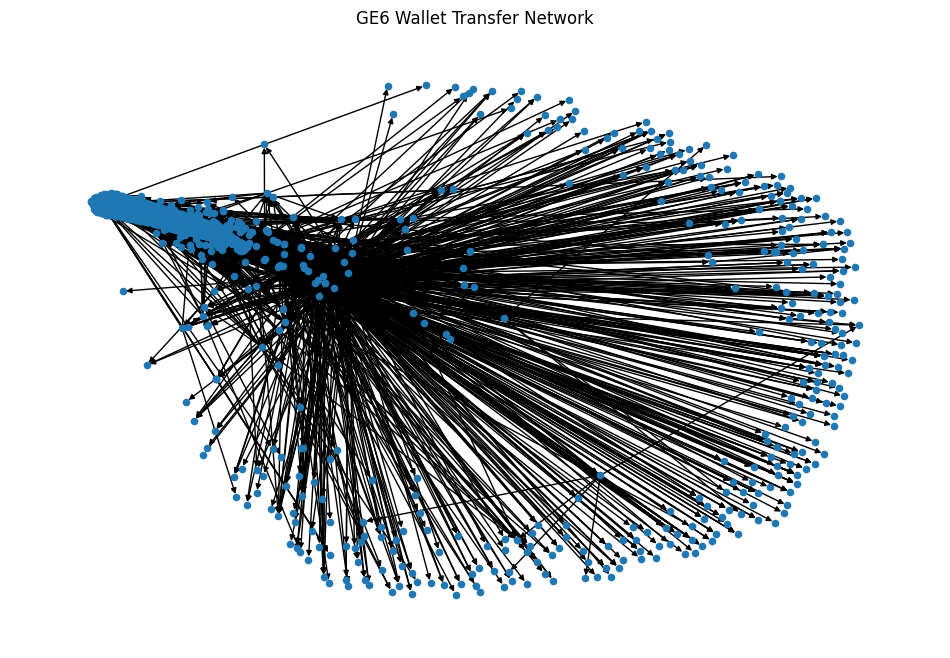

In [62]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.from_pandas_edgelist(
    edges,
    source='From',
    target='To',
    edge_attr=['transfer_amount', 'num_transactions'],
    create_using=nx.DiGraph()
)

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=False,
    node_size=20,
    arrows=True,
    arrowsize=8
)

plt.title('GE6 Wallet Transfer Network')
plt.axis('off')
plt.show()

In [63]:
import networkx as nx
from pyvis.network import Network
import pandas as pd

# 1. เตรียมข้อมูล
df = df_transfers.copy()
df['Value'] = pd.to_numeric(df['Value'], errors='coerce')
df = df.dropna(subset=['From', 'To', 'Value'])

# 2. รวมยอดโอนระหว่าง wallet คู่เดียวกัน
edges = (
    df.groupby(['From', 'To'], as_index=False)
      .agg(
          transfer_amount=('Value', 'sum'),
          num_transactions=('Tx Hash', 'count')
      )
)

# 3. เลือก 50 เส้นที่มียอดโอนสูงสุด
#top_edges = edges.nlargest(50, 'transfer_amount')

# 4. สร้างกราฟ
G = nx.from_pandas_edgelist(
    edges,
    source='From',
    target='To',
    edge_attr=['transfer_amount', 'num_transactions'],
    create_using=nx.DiGraph()
)

# 5. แปลงเป็น interactive HTML
net = Network(
    height='750px',
    width='100%',
    directed=True,
    notebook=False,
    bgcolor='#ffffff'
)

net.from_nx(G)

# 6. เพิ่มข้อมูลตอนเอาเมาส์ชี้เส้น
for edge in net.edges:
    edge['title'] = (
        f"Transfer amount: {edge['transfer_amount']:,.3f}"
        f"<br>Transactions: {edge['num_transactions']}"
    )
    edge['arrows'] = 'to'

# 7. บันทึกและเปิดไฟล์
net.show('ge6_network.html', notebook=False)

ge6_network.html


In [64]:
from pyvis.network import Network

net = Network(
    height="750px",
    width="100%",
    directed=True,
    bgcolor="#111827",
    font_color="white",
    notebook=False,
    cdn_resources="in_line"
)

net.from_nx(G)

# ปรับหน้าตา node และเส้น
for node in net.nodes:
    node["size"] = 12
    node["title"] = f"Wallet: {node['id']}"

for edge in net.edges:
    amount = edge.get("transfer_amount", 0)
    edge["title"] = f"Transfer amount: {amount:,.3f}"
    edge["arrows"] = "to"
    edge["color"] = "#64748b"

# ให้ node เคลื่อนที่หาตำแหน่งที่เหมาะสม
net.barnes_hut(
    gravity=-2500,
    central_gravity=0.3,
    spring_length=150,
    spring_strength=0.02,
    damping=0.09
)

from pathlib import Path

html = net.generate_html()

Path("ge6_network.html").write_text(
    html,
    encoding="utf-8"
)

net.show_buttons(filter_=["physics"])
#net.write_html("ge6_network.html", notebook=False)
#net.show('ge6_network.html', notebook=False)

# Analysis

C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\1494279433.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_sheet_df.groupby('vote_bins').agg(num_wallets = ('From','count')).plot(kind='bar', title='Distribution of Total Vote Amounts by Wallets', xlabel='Outbound Amount Bins', ylabel='Number of Wallets')
C:\Users\N678026\AppData\Local\Temp\ipykernel_27988\1494279433.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_sheet_df.groupby('vote_bins').agg(num_wallets = ('out_bound_vote_amount','sum')).plot(kind='bar', title='Distribution of Total Vote Amounts by Wallets', xlabel='Outbound Amo

<Axes: title={'center': 'Distribution of Total Vote Amounts by Wallets'}, xlabel='Outbound Amount Bins', ylabel='sum of vote amount'>

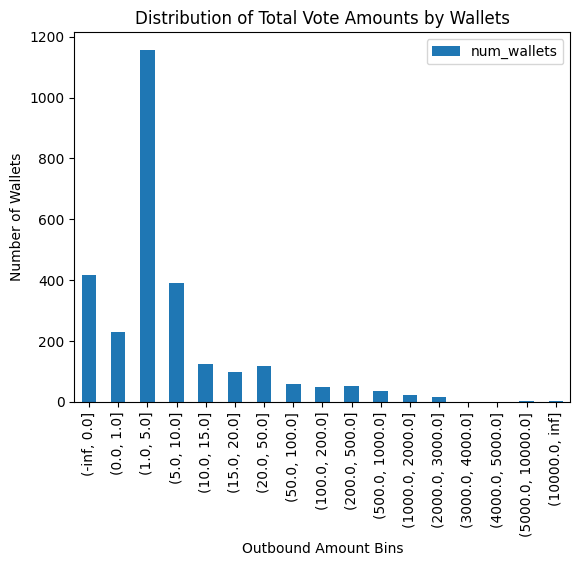

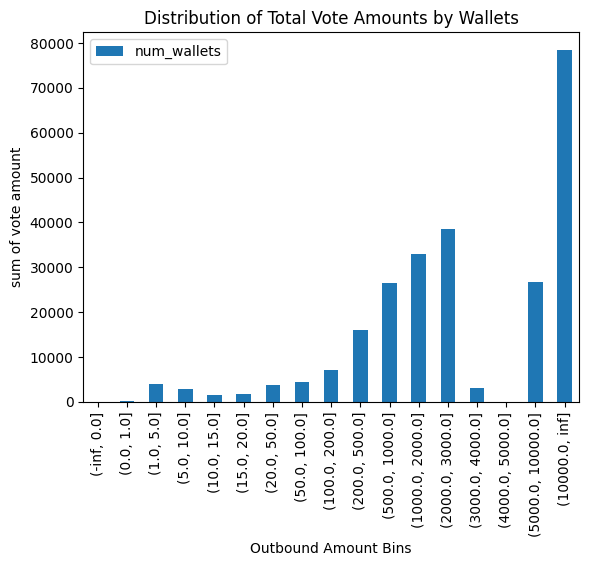

In [65]:
balance_sheet_df['vote_bins'] = pd.cut(balance_sheet_df['out_bound_vote_amount'],bins=[-float('inf'),0,1, 5,10,15,20,50, 100, 200, 500, 1000,2000,3000,4000,5000,10000, float('inf')], duplicates='drop')
balance_sheet_df.groupby('vote_bins').agg(num_wallets = ('From','count')).plot(kind='bar', title='Distribution of Total Vote Amounts by Wallets', xlabel='Outbound Amount Bins', ylabel='Number of Wallets')
balance_sheet_df.groupby('vote_bins').agg(num_wallets = ('out_bound_vote_amount','sum')).plot(kind='bar', title='Distribution of Total Vote Amounts by Wallets', xlabel='Outbound Amount Bins', ylabel='sum of vote amount')

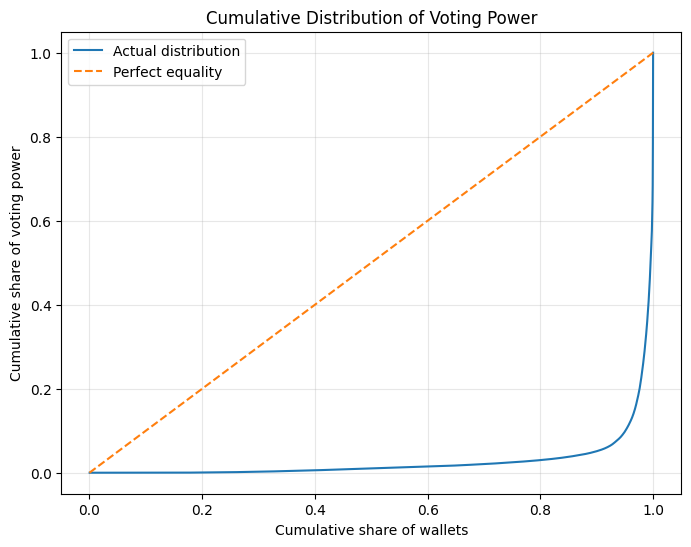

Gini: 0.9468


In [66]:
import numpy as np
import matplotlib.pyplot as plt

x = np.sort(balance_sheet_df['out_bound_vote_amount'].values)

cum_votes = np.cumsum(x)
cum_votes = cum_votes / cum_votes[-1]

cum_wallets = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(8, 6))

plt.plot(
    cum_wallets,
    cum_votes,
    label='Actual distribution'
)

plt.plot(
    [0, 1],
    [0, 1],
    '--',
    label='Perfect equality'
)

plt.xlabel('Cumulative share of wallets')
plt.ylabel('Cumulative share of voting power')
plt.title('Cumulative Distribution of Voting Power')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

x = np.sort(balance_sheet_df['out_bound_vote_amount'].values)

gini = (
    2 * np.sum((np.arange(1, len(x) + 1)) * x)
    / (len(x) * np.sum(x))
    - (len(x) + 1) / len(x)
)

print(f"Gini: {gini:.4f}")

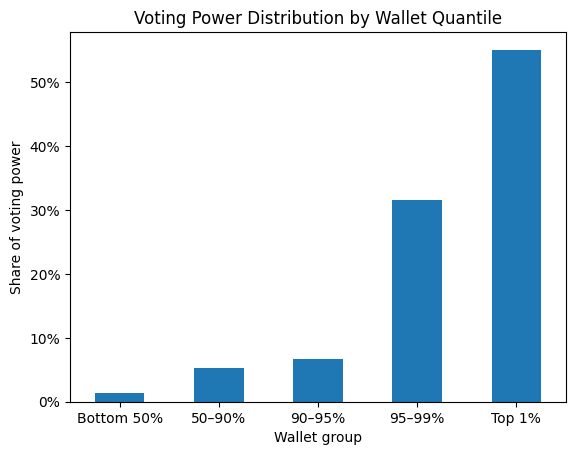

,quantile,min_vote,max_vote,num_wallets,total_vote,vote_share
0,Bottom 50%,1.0,5.0,1235,4148.000,0.013549
1,50–90%,6.0,98.0,882,16055.800,0.052443
2,90–95%,99.0,320.0,118,20478.211,0.066888
3,95–99%,322.0,2252.0,94,96726.600,0.315938
4,Top 1%,2380.0,53506.0,24,168747.989,0.551182


,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount,vote_bins,quantile
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,53506.0,2026-10-08,18.0,0.0,50720.0,2786.0,0.0,6.0,12.0,...,4000.00,0.0,0.000,53.0,0.0,0.0,5.060000e+02,53506.000,"(10000.0, inf]",Top 1%
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,74.00,0.0,1223.000,26.0,0.0,3.0,7.260000e+02,26189.000,"(10000.0, inf]",Top 1%
1490,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,10002.0,2026-10-04,7.0,0.0,6489.0,3513.0,0.0,2.0,5.0,...,3000.00,0.0,0.000,3.0,0.0,0.0,2.000000e+00,10002.000,"(5000.0, 10000.0]",Top 1%
98,0x0929A481B10376Ec340BBa2D44655Ad110223E99,9252.0,2026-10-08,9.0,0.0,8400.0,852.0,0.0,4.0,5.0,...,1.00,0.0,200.000,28.0,0.0,1.0,2.652000e+03,9052.000,"(5000.0, 10000.0]",Top 1%
1021,0x5dB8eD30baC5B2A46DC2A79dec7b00A2b7d3297b,6900.0,2026-09-28,1.0,0.0,6900.0,0.0,0.0,1.0,0.0,...,504.00,0.0,504.000,1.0,0.0,1.0,1.063000e+03,6396.000,"(5000.0, 10000.0]",Top 1%
2318,0xaB4d90d445d2a875c96831d6c4392aA80150aCEf,6090.0,2026-09-30,51.0,0.0,960.0,5130.0,0.0,1.0,50.0,...,300.00,0.0,0.000,3.0,0.0,0.0,5.159000e+03,6090.000,"(500.0, 1000.0]",Top 1%
1539,0x8c7a6d3Ae3b642a4596Bc51a6b352AeA722dA277,5425.0,2026-09-29,5.0,0.0,3048.0,2377.0,0.0,2.0,3.0,...,100.00,0.0,0.000,1.0,0.0,0.0,5.325000e+03,5425.000,"(50.0, 100.0]",Top 1%
1355,0x7f949c4Ab77706006c650DF0F2799243588BA894,5062.0,2026-10-08,11.0,0.0,5014.0,48.0,0.0,6.0,5.0,...,10.00,0.0,10.000,4.0,0.0,1.0,0.000000e+00,5052.000,"(5000.0, 10000.0]",Top 1%
213,0x142eb4268F95E36eD4D6103DCEEaCA5d8F400700,6225.0,2026-10-07,14.0,0.0,3080.0,3145.0,0.0,2.0,12.0,...,1.10,0.0,2602.900,5.0,0.0,1.0,1.000000e+03,3622.100,"(2000.0, 3000.0]",Top 1%
520,0x32C7E0BA1198c36Dd2f54c11908015EE05C8B22c,3763.0,2026-10-05,33.0,0.0,0.0,3763.0,0.0,0.0,33.0,...,249.00,0.0,249.000,1.0,0.0,1.0,4.440000e+02,3514.000,"(3000.0, 4000.0]",Top 1%


In [67]:
in_game_df = balance_sheet_df.query('out_bound_vote_amount > 0').copy()
in_game_df['quantile'] = pd.qcut(
    in_game_df['potential_vote_amount'],
    q=[0, 0.5, 0.9, 0.95, 0.99, 1],
    labels=[
        'Bottom 50%',
        '50–90%',
        '90–95%',
        '95–99%',
        'Top 1%'    
    ],
    duplicates='drop'
)

summary = (
    in_game_df
    .groupby('quantile', observed=True)['potential_vote_amount']
    .sum()
    .reset_index()
)

summary['vote_share'] = (
    summary['potential_vote_amount']
    / summary['potential_vote_amount'].sum()
)

# summary.plot(
#     x='quantile',
#     y='vote_share',
#     kind='bar',
#     legend=False
# )

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ax = summary.plot(
    x='quantile',
    y='vote_share',
    kind='bar',
    legend=False
)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Share of voting power')
ax.set_xlabel('Wallet group')
ax.set_title('Voting Power Distribution by Wallet Quantile')

plt.xticks(rotation=0)
plt.show()


range_summary = (
    in_game_df
    .groupby('quantile', observed=True)
    .agg(
        min_vote=('potential_vote_amount', 'min'),
        max_vote=('potential_vote_amount', 'max'),
        num_wallets=('potential_vote_amount', 'size'),
        total_vote=('potential_vote_amount', 'sum')
    )
    .reset_index()
)

range_summary['vote_share'] = (
    range_summary['total_vote']
    / range_summary['total_vote'].sum()
)

display(range_summary)

in_game_df.query('quantile == "Top 1%"').sort_values(by='potential_vote_amount',ascending=False)

In [68]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(official_accs+[vote_acc])].sort_values(by='in_bound_amount')[['From','in_bound_amount','out_bound_amount']]

,From,in_bound_amount,out_bound_amount
790,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1202.000000,541.0
964,0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc,10803.000000,3411.0
2552,0xd754a0bFF84998306f306DA12a3eEedbDD8abf41,10803.000000,3354.0
1512,0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4,16203.000000,5385.0
2300,0xa66e830BC83c98A78AC20D1b705E8abE1C768195,16203.000000,5346.0
1573,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,50001.000000,2603.0
2699,0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB,96003.000000,30423.0
915,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,144003.000000,47808.0
1445,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,248267.406163,0.0
805,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,800004.000000,39532.0


In [69]:
balance_sheet_df.loc[balance_sheet_df['From'].isin(official_accs+[vote_acc])]['out_bound_amount'].sum()

np.float64(387563.0)

In [70]:
df_transfers.query(f'To == "{hof}"')['From'].unique()

array(['0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
       '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
       '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
       '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148',
       '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
       '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc'], dtype=object)

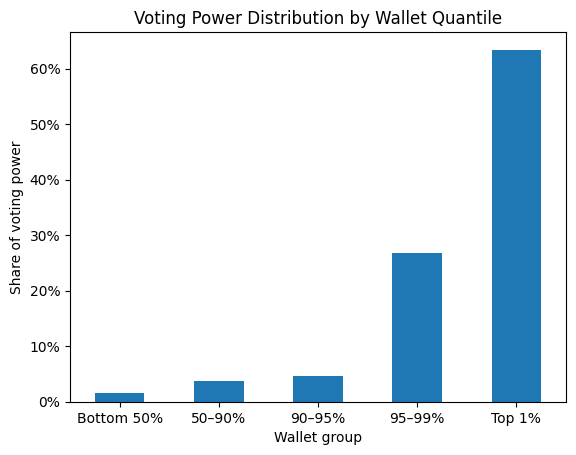

In [71]:
balance_sheet_df['quantile'] = pd.qcut(
    balance_sheet_df['out_bound_vote_amount'],
    q=[0, 0.5, 0.9, 0.95, 0.99, 1],
    labels=[
        'Bottom 50%',
        '50–90%',
        '90–95%',
        '95–99%',
        'Top 1%'    
    ],
    duplicates='drop'
)

summary = (
    balance_sheet_df
    .groupby('quantile', observed=True)['out_bound_vote_amount']
    .sum()
    .reset_index()
)

summary['vote_share'] = (
    summary['out_bound_vote_amount']
    / summary['out_bound_vote_amount'].sum()
)

# summary.plot(
#     x='quantile',
#     y='vote_share',
#     kind='bar',
#     legend=False
# )

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ax = summary.plot(
    x='quantile',
    y='vote_share',
    kind='bar',
    legend=False
)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Share of voting power')
ax.set_xlabel('Wallet group')
ax.set_title('Voting Power Distribution by Wallet Quantile')

plt.xticks(rotation=0)
plt.show()

In [72]:
balance_sheet_df['out_bound_vote_amount'].quantile([0.5, 0.9, 0.95, 0.99])

0.50       4.00
0.90      36.00
0.95     189.20
0.99    1631.96
Name: out_bound_vote_amount, dtype: float64

In [73]:
balance_sheet_df.query('quantile == "Top 1%"')

,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount,vote_bins,quantile
58,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,27412.0,2026-10-11,22.0,0.0,27184.0,228.0,0.0,4.0,18.0,...,74.0,0.0,1223.000,26.0,0.0,3.0,7.260000e+02,26189.000,"(10000.0, inf]",Top 1%
98,0x0929A481B10376Ec340BBa2D44655Ad110223E99,9252.0,2026-10-08,9.0,0.0,8400.0,852.0,0.0,4.0,5.0,...,1.0,0.0,200.000,28.0,0.0,1.0,2.652000e+03,9052.000,"(5000.0, 10000.0]",Top 1%
116,0x0CAC2bB76ac49B17ad374E678855837E125026A4,53506.0,2026-10-08,18.0,0.0,50720.0,2786.0,0.0,6.0,12.0,...,4000.0,0.0,0.000,53.0,0.0,0.0,5.060000e+02,53506.000,"(10000.0, inf]",Top 1%
213,0x142eb4268F95E36eD4D6103DCEEaCA5d8F400700,6225.0,2026-10-07,14.0,0.0,3080.0,3145.0,0.0,2.0,12.0,...,1.1,0.0,2602.900,5.0,0.0,1.0,1.000000e+03,3622.100,"(2000.0, 3000.0]",Top 1%
285,0x1C79A41A9319510fd549b1e8084B5DB14a05028B,2252.0,2026-10-04,9.0,0.0,0.0,2252.0,0.0,0.0,9.0,...,8.0,0.0,0.000,15.0,0.0,0.0,1.000000e+00,2252.000,"(2000.0, 3000.0]",Top 1%
436,0x2A8eE1BEBBbf499E4d9D9A43B98f2C54FDe98157,2380.0,2026-10-02,4.0,0.0,2380.0,0.0,0.0,4.0,0.0,...,555.0,0.0,0.000,3.0,0.0,0.0,1.600000e+02,2380.000,"(2000.0, 3000.0]",Top 1%
471,0x2a14051C54F10E3c705da85E690760c081c78070,2075.0,2026-10-03,5.0,0.0,1972.0,103.0,0.0,3.0,2.0,...,37.0,0.0,0.000,2.0,0.0,0.0,0.000000e+00,2075.000,"(2000.0, 3000.0]",Top 1%
520,0x32C7E0BA1198c36Dd2f54c11908015EE05C8B22c,3763.0,2026-10-05,33.0,0.0,0.0,3763.0,0.0,0.0,33.0,...,249.0,0.0,249.000,1.0,0.0,1.0,4.440000e+02,3514.000,"(3000.0, 4000.0]",Top 1%
604,0x391fbf81438BA4670aa50156015e1151D820Dadd,3043.0,2026-10-03,4.0,0.0,3001.0,42.0,0.0,2.0,2.0,...,12.0,0.0,24.000,1.0,0.0,4.0,1.900000e+01,3019.000,"(2000.0, 3000.0]",Top 1%
654,0x3b426f905bFAdD954309e551cE426f5D322021ed,4904.0,2026-10-11,286.0,0.0,2648.0,2256.0,0.0,6.0,280.0,...,199.0,0.0,2400.000,6.0,0.0,4.0,5.000000e+00,2504.000,"(2000.0, 3000.0]",Top 1%


In [74]:
range_summary = (
    balance_sheet_df
    .groupby('quantile', observed=True)
    .agg(
        min_vote=('out_bound_vote_amount', 'min'),
        max_vote=('out_bound_vote_amount', 'max'),
        num_wallets=('out_bound_vote_amount', 'size'),
        total_vote=('out_bound_vote_amount', 'sum')
    )
    .reset_index()
)

range_summary['vote_share'] = (
    range_summary['total_vote']
    / range_summary['total_vote'].sum()*100
)

range_summary

,quantile,min_vote,max_vote,num_wallets,total_vote,vote_share
0,Bottom 50%,0.0,4.0,1724,3892.266441,1.567772
1,50–90%,4.2,36.0,774,9046.519922,3.643861
2,90–95%,38.0,188.0,132,11331.191000,4.564107
3,95–99%,190.0,1631.0,111,66618.130000,26.833216
4,Top 1%,1634.0,53000.0,28,157379.298800,63.391043


In [75]:
53000/balance_sheet_df['out_bound_vote_amount'].sum()

np.float64(0.2134794930153567)

In [76]:
potential_buu = ["0xa6420EF2230685b2A4838278B70deE66e1911619","0x91eF5e8A8Ff131CB9Ab9Cb236BE88FF620974583","0xa6B550336f8B71091B99956762D38FE79E927534","0x9233A859cc307678FBca7605637A6B92ACBb5Ce6",
                 "0xc52d82A21d96Adf95223838Afb710B95D2a82409","0xA6AB54709D58fA2aaBDcdCFdBAa45BcDbA039994","0xf11f5a15517da10bFE6F933B575d64B9C82AF75E","0x749f333D07b4cEaD1d4E0068b2c533fEDeE59Aa5"]
potential_hof = ["0x7dbE0F87cD65AFDAce05b3F7645386439BB315eF",
                 "0xEb5cf98326CDbb2Abe26BBff8FB69bf0AF5a3354",
                 "0xfe0F56dd0BB2393F294015482175f212DE230343"]

balance_sheet_df.loc[balance_sheet_df['From'].isin(potential_buu)]#['potential_vote_amount'].sum()


,From,in_bound_amount,last_in_bound_date,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,min_out_bound_amount,out_bound_transfer_amount,out_bound_multipleTransfer_amount,out_bound_is_vote,out_bound_is_transfer,out_bound_is_multipleTransfer,balance,potential_vote_amount,vote_bins,quantile
1591,0x91eF5e8A8Ff131CB9Ab9Cb236BE88FF620974583,949.0,2026-10-06,8.0,0.0,0.0,949.0,0.0,0.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,949.0,949.0,"(-inf, 0.0]",Bottom 50%
1775,0xA6AB54709D58fA2aaBDcdCFdBAa45BcDbA039994,258.0,2026-10-02,1.0,0.0,0.0,258.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,258.0,258.0,"(-inf, 0.0]",Bottom 50%
2302,0xa6B550336f8B71091B99956762D38FE79E927534,550.0,2026-10-01,4.0,0.0,0.0,550.0,0.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,550.0,550.0,"(-inf, 0.0]",Bottom 50%
2460,0xc52d82A21d96Adf95223838Afb710B95D2a82409,30.0,2026-09-27,1.0,0.0,0.0,30.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,30.0,30.0,"(-inf, 0.0]",Bottom 50%


In [77]:
for p in [0.01, 0.05, 0.10,0.5]:
    n = int(len(balance_sheet_df) * p)
    share = (
        balance_sheet_df
        .nlargest(n, 'out_bound_vote_amount')['out_bound_vote_amount']
        .sum()
        / balance_sheet_df['out_bound_vote_amount'].sum()
    )
    print(f"Top {p:.0%}: {share:.2%}")

Top 1%: 62.73%
Top 5%: 90.15%
Top 10%: 94.86%
Top 50%: 98.98%


In [78]:
df_transfers['latest_vote_amount_by_wallet'] = df_transfers.groupby(['From'])['vote_amount'].transform('max')